# Topology-Aware Swin-UNet: Multi-Task Retinal Vessel + Artery–Vein Segmentation, CIMT Classification and CIMT Regression

### Complete, fixed, run-top-to-bottom notebook (Kaggle / single GPU)

| Task | Output | Type |
|---|---|---|
| **Task 1** | CIMT Classification | Binary (Class 0 / Class 1) |
| **Task 2** | CIMT Regression | Continuous thickness (mm) |
| **Task 3** | Vessel Segmentation | Binary mask + **topology-aware** losses (soft-clDice, thin/branch weighted BCE) |
| **Task 4** | **Artery–Vein Segmentation** | 3-class (Background / Artery / Vein) |

**Figures:** 1 Dataset · 2 Architecture · 3 Test performance · 4 Qualitative · 5 Topology · 6 Training curves  
**Tables:** 1 Dataset · 2 Implementation · 3 Complexity · 4 Main results (95 % CI) · 5 Subgroups · 6 Topology / A/V

All figures: Times New Roman 12 pt bold, exported as 600 dpi PNG + PDF + TIFF.

## 1. Setup

In [1]:
import os, re, json, time, random, math, warnings, zipfile, shutil, sys
import numpy as np, pandas as pd
from PIL import Image
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, Patch
import seaborn as sns
from IPython.display import display, HTML
from contextlib import contextmanager

import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

from scipy.stats import pearsonr
from sklearn.metrics import (roc_auc_score, roc_curve, precision_recall_curve, average_precision_score,
                             matthews_corrcoef, brier_score_loss, confusion_matrix)
from sklearn.calibration import calibration_curve

warnings.filterwarnings("ignore")

# ---- small self-contained helpers (no timm dependency -> no import errors on Kaggle) ----
def to_2tuple(x):
    return tuple(x) if isinstance(x, (tuple, list)) else (x, x)

def trunc_normal_(t, mean=0., std=1., a=-2., b=2.):
    return nn.init.trunc_normal_(t, mean=mean, std=std, a=a, b=b)

class DropPath(nn.Module):
    def __init__(self, drop_prob=0.):
        super().__init__()
        self.drop_prob = float(drop_prob)
    def forward(self, x):
        if self.drop_prob == 0. or not self.training:
            return x
        keep = 1. - self.drop_prob
        shape = (x.shape[0],) + (1,) * (x.ndim - 1)
        mask = x.new_empty(shape).bernoulli_(keep)
        return x * mask / keep

def set_seed(seed=42):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)

set_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device, "| torch", torch.__version__)
if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

Device: cuda | torch 2.11.0+cu130
GPU: Tesla T4


## 2. Config and switches

In [2]:
CFG = dict(
    images_dir = "/kaggle/input/datasets/rofikbme/fundus-image/Fundus_CIMT_2903 Dataset/Fundus_CIMT_2903 Dataset",
    masks_dir  = "/kaggle/input/datasets/rofikbme/fundus-image/predicted_masks_5806",
    csv_path   = "/kaggle/input/datasets/rofikbme/fundus-image/data_info.csv",
    av_masks_dir = "/kaggle/input/datasets/amimulhasan/fundus-imagel/Fundus_A and V/Fundus_A and V",
    out_dir    = "/kaggle/working",
    img_size   = 512,          # must be divisible by 32 * window_size / 8  (512 and 256 are safe)
    batch_size = 4,            # 8 at 512 px usually OOMs on a 16 GB GPU (T4/P100)
    epochs     = 30,
    patience   = 10,           # early stopping on validation loss
    lr         = 1e-4,
    weight_decay = 1e-5,
    grad_clip  = 1.0,
    num_workers = 2,
    # Swin-UNet
    embed_dim  = 96,
    depths     = [2, 2, 2, 2],
    depths_decoder = [1, 2, 2, 2],
    num_heads  = [3, 6, 12, 24],
    window_size = 8,
    drop_path_rate = 0.1,
    # loss weights
    lam        = 0.5,   # seg: (1-lam)*BCE + lam*Dice
    w_cl       = 0.5,   # soft-clDice
    w_wb       = 0.5,   # thin/branch weighted BCE
    cl_iters   = 10,    # soft-skeleton iterations
    thin_boost = 2.0,
    branch_boost = 4.0,
    w_seg = 1.0, w_cls = 1.0, w_reg = 1.0, w_av = 1.0,
    boot_iters = 1000,  # patient-level bootstrap resamples
    amp        = True,
    seed       = 42,
    debug      = False,
)

RUN_TRAINING  = True      # False -> load the saved best checkpoint and only evaluate
CKPT_DIR      = CFG["out_dir"]
GENDER_NAMES  = {0: "Gender 0", 1: "Gender 1"}
CLASS_NAMES   = {0: "Class 0", 1: "Class 1"}
AV_CLASS_NAMES = {0: "Background", 1: "Artery", 2: "Vein"}

if CFG["debug"]:
    CFG.update(epochs=2, img_size=128, batch_size=4, boot_iters=50)
assert CFG["img_size"] % 32 == 0, "img_size must be divisible by 32"

os.makedirs(CFG["out_dir"], exist_ok=True)
set_seed(CFG["seed"])
USE_AMP = bool(CFG["amp"] and device.type == "cuda")

def autocast_ctx():
    return torch.autocast(device_type="cuda", dtype=torch.float16, enabled=USE_AMP)

def make_scaler():
    try:
        return torch.amp.GradScaler("cuda", enabled=USE_AMP)
    except Exception:
        return torch.cuda.amp.GradScaler(enabled=USE_AMP)

print({k: v for k, v in CFG.items() if not k.endswith("_dir") and k != "csv_path"})

{'img_size': 512, 'batch_size': 4, 'epochs': 30, 'patience': 10, 'lr': 0.0001, 'weight_decay': 1e-05, 'grad_clip': 1.0, 'num_workers': 2, 'embed_dim': 96, 'depths': [2, 2, 2, 2], 'depths_decoder': [1, 2, 2, 2], 'num_heads': [3, 6, 12, 24], 'window_size': 8, 'drop_path_rate': 0.1, 'lam': 0.5, 'w_cl': 0.5, 'w_wb': 0.5, 'cl_iters': 10, 'thin_boost': 2.0, 'branch_boost': 4.0, 'w_seg': 1.0, 'w_cls': 1.0, 'w_reg': 1.0, 'w_av': 1.0, 'boot_iters': 1000, 'amp': True, 'seed': 42, 'debug': False}


## 3. Journal formatting helpers

In [3]:
import logging
logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)
FIG_DPI, SAVE_TIFF = 600, True
Image.MAX_IMAGE_PIXELS = None
FS = 12

sns.set_theme(style="ticks", context="notebook", palette="colorblind")
mpl.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Times New Roman", "Times", "Liberation Serif", "DejaVu Serif", "Nimbus Roman", "serif"],
    "font.size": FS, "font.weight": "bold",
    "axes.titlesize": FS, "axes.titleweight": "bold",
    "axes.labelsize": FS, "axes.labelweight": "bold",
    "xtick.labelsize": FS, "ytick.labelsize": FS,
    "legend.fontsize": FS, "legend.title_fontsize": FS, "legend.frameon": False,
    "figure.titlesize": FS, "figure.titleweight": "bold",
    "axes.linewidth": 1.5, "xtick.major.width": 1.5, "ytick.major.width": 1.5,
    "xtick.major.size": 5, "ytick.major.size": 5, "lines.linewidth": 2.0,
    "axes.spines.top": False, "axes.spines.right": False,
    "figure.dpi": 110, "savefig.dpi": 600, "savefig.bbox": "tight", "savefig.pad_inches": 0.05,
    "savefig.facecolor": "white", "figure.facecolor": "white",
    "pdf.fonttype": 42, "ps.fonttype": 42,
    "mathtext.fontset": "stix", "mathtext.default": "bf",
})
PAL = sns.color_palette("colorblind")

FIG_DIR = os.path.join(CFG["out_dir"], "journal_figures")
TAB_DIR = os.path.join(CFG["out_dir"], "journal_tables")
for _d in (FIG_DIR, TAB_DIR):
    os.makedirs(_d, exist_ok=True)
FIG_REGISTRY, TAB_REGISTRY = [], []

def _slot(registry, stem):
    for i, r in enumerate(registry):
        if r["stem"] == stem:
            return i + 1, i
    return len(registry) + 1, None

def say(text):
    display(HTML(f'<p style="font-size:12pt;font-weight:bold;font-family:Times New Roman,serif;margin:6px 0">{text}</p>'))

def ttl(ax, tag, text):
    ax.set_title(f"({tag}) {text}", loc="left", fontsize=FS, fontweight="bold", fontfamily="serif")

def save_fig(fig, stem, caption, dpi=None):
    n, old = _slot(FIG_REGISTRY, stem)
    dpi = dpi or FIG_DPI
    base = os.path.join(FIG_DIR, f"Fig{n:02d}_{stem}")
    fig.savefig(base + ".png", dpi=dpi)
    fig.savefig(base + ".pdf")
    tif = None
    if SAVE_TIFF:
        try:
            fig.savefig(base + ".tiff", dpi=dpi, pil_kwargs={"compression": "tiff_lzw"})
            tif = base + ".tiff"
        except Exception as e:
            print("  (TIFF export skipped:", type(e).__name__, e, ")")
    rec = dict(no=n, label=f"Fig. {n}", stem=stem, caption=caption,
               png=base + ".png", pdf=base + ".pdf", tiff=tif)
    if old is None:
        FIG_REGISTRY.append(rec)
    else:
        FIG_REGISTRY[old] = rec
    plt.show()
    display(HTML(
        f'<p style="font-size:12pt;font-weight:bold;font-family:Times New Roman,serif;margin:4px 0 18px 0">'
        f'Fig. {n}. {caption}</p>'))

def _table_css(align):
    return [
        {"selector": "", "props": [("border-collapse", "collapse"),
                                   ("border-top", "2px solid currentColor"),
                                   ("border-bottom", "2px solid currentColor"),
                                   ("margin", "4px 0 6px 0"),
                                   ("font-family", "Times New Roman, serif")]},
        {"selector": "th", "props": [("font-size", "12pt"), ("font-weight", "bold"),
                                     ("text-align", "center"),
                                     ("border-bottom", "1.5px solid currentColor"),
                                     ("padding", "5px 14px"),
                                     ("background-color", "transparent"),
                                     ("font-family", "Times New Roman, serif")]},
        {"selector": "td", "props": [("font-size", "12pt"), ("font-weight", "bold"),
                                     ("text-align", align), ("padding", "4px 14px"),
                                     ("border", "none"),
                                     ("font-family", "Times New Roman, serif")]},
    ]

def show_table(df, stem, caption, index=False, precision=4, note=None, align="center",
               best_max=(), best_min=()):
    n, old = _slot(TAB_REGISTRY, stem)
    base = os.path.join(TAB_DIR, f"Table{n:02d}_{stem}")
    df.to_csv(base + ".csv", index=index)
    try:
        df.to_latex(base + ".tex", index=index, escape=True,
                    caption=caption.replace("%", r"\%"), label=f"tab:{stem}",
                    float_format=lambda v: f"{v:.{precision}f}")
    except Exception as e:
        print("  (LaTeX export skipped:", type(e).__name__, ")")
    rec = dict(no=n, label=f"Table {n}", stem=stem, caption=caption, df=df.copy(),
               index=index, precision=precision, note=note,
               csv=base + ".csv", tex=base + ".tex")
    if old is None:
        TAB_REGISTRY.append(rec)
    else:
        TAB_REGISTRY[old] = rec
    display(HTML(
        f'<p style="font-size:12pt;font-weight:bold;font-family:Times New Roman,serif;margin:12px 0 2px 0">'
        f'Table {n}. {caption}</p>'))
    sty = df.style
    if not index:
        sty = sty.hide(axis="index")
    sty = sty.format(precision=precision, na_rep="–").set_table_styles(_table_css(align))
    if best_max:
        sty = sty.highlight_max(subset=list(best_max), props="text-decoration: underline;")
    if best_min:
        sty = sty.highlight_min(subset=list(best_min), props="text-decoration: underline;")
    display(sty)
    if note:
        display(HTML(
            f'<p style="font-size:12pt;font-weight:bold;font-family:Times New Roman,serif;margin:2px 0 14px 0">'
            f'{note}</p>'))

def fmt_ci(m, lo, hi, d=4):
    return f"{m:.{d}f} ({lo:.{d}f}–{hi:.{d}f})"

def nm(x):
    x = np.asarray(x, dtype=float)
    return float(np.nanmean(x)) if np.isfinite(x).any() else float("nan")

@contextmanager
def safe(name):
    try:
        yield
    except Exception as e:
        import traceback
        traceback.print_exc()
        print(f"\n[WARNING] section '{name}' failed and was skipped: {type(e).__name__}: {e}")

print("Journal style ready: Times New Roman | 12 pt bold | 600 dpi | figures ->", FIG_DIR)

Journal style ready: Times New Roman | 12 pt bold | 600 dpi | figures -> /kaggle/working/journal_figures


## 4. Data (Table 1, Fig. 1)
Patient-level split from the CSV `group` column (1 = train, 2 = val, 3 = test) with a hard leakage assert. Rows whose image or vessel mask is missing on disk are dropped (and reported) instead of crashing mid-epoch.

indexed images=5806 masks=5806
csv: (5806, 7)


,image_name,thickness,label,True_age,age,gender,group
0,2491006_R.png,0.8,0,63,0.684932,0,1
1,2491006_L.png,0.8,0,63,0.684932,0,1
2,3730004_R.png,1.2,1,61,0.657534,1,1
3,3730004_L.png,1.2,1,61,0.657534,1,1
4,3730006_R.png,1.2,1,64,0.698630,1,1


rows with image+mask on disk: 5806/5806  (dropped 0)
patients train/val/test = 2603/200/100 | overlap = 0
images   train/val/test = 5206/400/200
{'age_mu': 48.09873223203996, 'age_sd': 12.819887685260232, 't_mu': 0.9951325393776411, 't_sd': 0.18354104606772081}
label counts (train): {1: 3808, 0: 1398}


Split,Patients,Images,"Age, years (mean ± SD)","Gender 1, n (%)","Class 1, n (%)","CIMT, mm (mean ± SD)"
Training,2603,5206,48.1 ± 12.8,3374 (64.8%),3808 (73.1%),1.00 ± 0.18
Validation,200,400,46.7 ± 13.3,224 (56.0%),200 (50.0%),0.92 ± 0.21
Test,100,200,46.4 ± 14.5,126 (63.0%),100 (50.0%),0.91 ± 0.19
Total,2903,5806,47.9 ± 12.9,3724 (64.1%),4108 (70.8%),0.99 ± 0.19


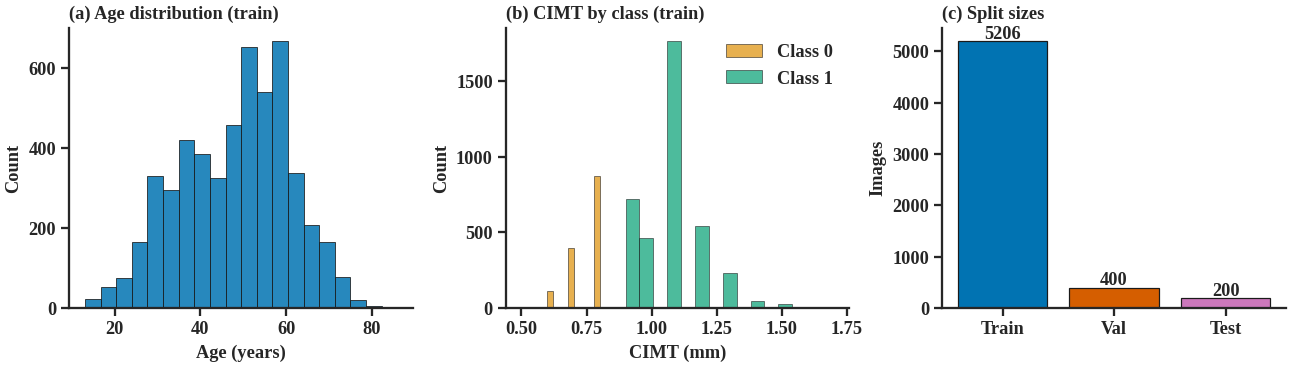

In [4]:
IMG_EXTS = (".png", ".jpg", ".jpeg", ".tif", ".tiff", ".bmp")

def index_dir(root):
    # stem -> full path (recursive). First hit wins.
    idx = {}
    for dp, _, fns in os.walk(root):
        for fn in sorted(fns):
            stem, ext = os.path.splitext(fn)
            if ext.lower() in IMG_EXTS and stem not in idx:
                idx[stem] = os.path.join(dp, fn)
    return idx

for k in ("images_dir", "masks_dir", "csv_path"):
    assert os.path.exists(CFG[k]), f"CFG['{k}'] not found: {CFG[k]}"
IMG_INDEX  = index_dir(CFG["images_dir"])
MASK_INDEX = index_dir(CFG["masks_dir"])
print(f"indexed images={len(IMG_INDEX)} masks={len(MASK_INDEX)}")

def get_patient_id(base_name):
    return re.sub(r'(_L|_R|_OD|_OS)$', '', base_name, flags=re.IGNORECASE)

def mask_key(base):
    return base + "_mask" if (base + "_mask") in MASK_INDEX else (base if base in MASK_INDEX else None)

df = pd.read_csv(CFG["csv_path"])
print("csv:", df.shape)
display(df.head())

AGE_COL = "True_age" if "True_age" in df.columns else "age"
need = ["image_name", "group", "label", "thickness", "gender", AGE_COL]
miss = [c for c in need if c not in df.columns]
assert not miss, f"CSV is missing columns: {miss}"
df = df.dropna(subset=need).copy()

df["base"] = df["image_name"].apply(lambda x: os.path.splitext(str(x))[0])
ok = df["base"].isin(set(IMG_INDEX.keys())) & df["base"].apply(lambda b: mask_key(b) is not None)
print(f"rows with image+mask on disk: {int(ok.sum())}/{len(df)}  (dropped {int((~ok).sum())})")
assert ok.sum() > 0, "No CSV row matches an image + vessel mask. Check images_dir / masks_dir naming."
df = df[ok].reset_index(drop=True)

df["patient"] = df["base"].apply(get_patient_id)
df["group"] = df["group"].astype(int)
train_df = df[df["group"] == 1].reset_index(drop=True)
val_df   = df[df["group"] == 2].reset_index(drop=True)
test_df  = df[df["group"] == 3].reset_index(drop=True)
assert min(len(train_df), len(val_df), len(test_df)) > 0, "A split is empty (check the 'group' column)."

p_tr, p_va, p_te = set(train_df["patient"]), set(val_df["patient"]), set(test_df["patient"])
assert len(p_tr & p_va) == 0 and len(p_tr & p_te) == 0 and len(p_va & p_te) == 0, "patient leakage!"
print(f"patients train/val/test = {len(p_tr)}/{len(p_va)}/{len(p_te)} | overlap = 0")
print(f"images   train/val/test = {len(train_df)}/{len(val_df)}/{len(test_df)}")

SCALER = dict(
    age_mu = float(train_df[AGE_COL].mean()),
    age_sd = float(train_df[AGE_COL].std() + 1e-8),
    t_mu   = float(train_df["thickness"].mean()),
    t_sd   = float(train_df["thickness"].std() + 1e-8),
)
print(SCALER)
print("label counts (train):", train_df["label"].value_counts().to_dict())

def _summ(split_df, name):
    n_pat = split_df["patient"].nunique(); n_img = len(split_df)
    g1 = int((split_df["gender"] == 1).sum()); c1 = int((split_df["label"] == 1).sum())
    return {
        "Split": name, "Patients": n_pat, "Images": n_img,
        "Age, years (mean ± SD)": f"{split_df[AGE_COL].mean():.1f} ± {split_df[AGE_COL].std():.1f}",
        "Gender 1, n (%)": f"{g1} ({100 * g1 / max(n_img, 1):.1f}%)",
        "Class 1, n (%)": f"{c1} ({100 * c1 / max(n_img, 1):.1f}%)",
        "CIMT, mm (mean ± SD)": f"{split_df['thickness'].mean():.2f} ± {split_df['thickness'].std():.2f}",
    }

tab1 = pd.DataFrame([_summ(train_df, "Training"), _summ(val_df, "Validation"),
                     _summ(test_df, "Test"), _summ(df, "Total")])
show_table(tab1, "dataset_characteristics",
           "Characteristics of the fundus-image dataset and the patient-level train / validation / test split.",
           note="Both eyes of a patient are always in the same split (verified, no patient overlap). CIMT = carotid intima-media thickness. A/V masks come from the Fundus_A and V dataset.")

# ---------- Fig. 1 Dataset overview ----------
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))
axes[0].hist(train_df[AGE_COL], bins=20, color=PAL[0], alpha=0.85, edgecolor="k", linewidth=0.6)
axes[0].set_xlabel("Age (years)"); axes[0].set_ylabel("Count")
ttl(axes[0], "a", "Age distribution (train)")
for lab, col in [(0, PAL[1]), (1, PAL[2])]:
    sub = train_df[train_df["label"] == lab]["thickness"]
    axes[1].hist(sub, bins=15, alpha=0.7, color=col, label=CLASS_NAMES.get(lab, str(lab)), edgecolor="k", linewidth=0.5)
axes[1].set_xlabel("CIMT (mm)"); axes[1].set_ylabel("Count"); axes[1].legend(frameon=False)
ttl(axes[1], "b", "CIMT by class (train)")
sizes = [len(train_df), len(val_df), len(test_df)]
axes[2].bar(["Train", "Val", "Test"], sizes, color=[PAL[0], PAL[3], PAL[4]], edgecolor="k", linewidth=0.8)
axes[2].set_ylabel("Images")
for i, v in enumerate(sizes):
    axes[2].text(i, v + max(sizes) * 0.01, str(v), ha="center", fontweight="bold", fontsize=FS)
ttl(axes[2], "c", "Split sizes")
plt.tight_layout()
save_fig(fig, "dataset_overview",
         "Dataset overview. (a) Age distribution in the training set. (b) CIMT distribution by disease class. (c) Number of images per split.")

## 5. Dataset and data loaders (vessel mask + A/V mask)

In [5]:
def _load_av_mask(av_dir, base, size):
    # Returns (H,W) int64 with 0=background, 1=artery, 2=vein, or None if no A/V annotation exists.
    if av_dir is None or not os.path.isdir(av_dir):
        return None
    candidates = [os.path.join(av_dir, base + sfx) for sfx in ("_av.png", "_AV.png", ".png", "_av.bmp", ".bmp")]
    for p in candidates:
        if os.path.isfile(p):
            m = np.asarray(Image.open(p).resize((size, size), Image.NEAREST))
            if m.ndim == 3:
                r, g, b = [m[..., i].astype(float) for i in range(3)]
                out = np.zeros(m.shape[:2], dtype=np.int64)
                out[(r > 120) & (r > g) & (r > b)] = 1      # red  -> artery
                out[(b > 120) & (b > r) & (b > g)] = 2      # blue -> vein
                return out
            m = m.astype(np.float32)
            if m.max() > 2:
                m = m / 255.0
            out = np.zeros(m.shape, dtype=np.int64)
            out[m > 0.6] = 2
            out[(m > 0.2) & (m <= 0.6)] = 1
            return out
    art_p = [os.path.join(av_dir, base + "_artery.png"), os.path.join(av_dir, "artery", base + ".png"),
             os.path.join(av_dir, "Artery", base + ".png")]
    vein_p = [os.path.join(av_dir, base + "_vein.png"), os.path.join(av_dir, "vein", base + ".png"),
              os.path.join(av_dir, "Vein", base + ".png")]
    art = next((p for p in art_p if os.path.isfile(p)), None)
    vein = next((p for p in vein_p if os.path.isfile(p)), None)
    if art is None and vein is None:
        return None
    out = np.zeros((size, size), dtype=np.int64)
    if art is not None:
        out[np.asarray(Image.open(art).convert("L").resize((size, size), Image.NEAREST)) > 127] = 1
    if vein is not None:
        out[np.asarray(Image.open(vein).convert("L").resize((size, size), Image.NEAREST)) > 127] = 2
    return out


class MTDataset(Dataset):
    def __init__(self, df, img_size=512, augment=False, scaler=None, av_dir=None, name=""):
        self.df = df.reset_index(drop=True)
        self.img_size = img_size
        self.augment = augment
        self.sc = scaler if scaler is not None else SCALER
        self.av_dir = av_dir
        n_probe = min(80, len(self.df))
        n_av = sum(_load_av_mask(av_dir, self.df.iloc[i]["base"], 32) is not None for i in range(n_probe))
        print(f"  [{name}] A/V mask probe: {n_av}/{n_probe} found")

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        base, s = row["base"], self.img_size
        img = Image.open(IMG_INDEX[base]).convert("RGB").resize((s, s), Image.BILINEAR)
        mask = Image.open(MASK_INDEX[mask_key(base)]).convert("L").resize((s, s), Image.NEAREST)
        av = _load_av_mask(self.av_dir, base, s)

        if self.augment:
            if random.random() < 0.5:
                img = img.transpose(Image.FLIP_LEFT_RIGHT)
                mask = mask.transpose(Image.FLIP_LEFT_RIGHT)
                if av is not None:
                    av = np.ascontiguousarray(np.fliplr(av))
            if random.random() < 0.5:
                a = random.uniform(-15, 15)
                img = img.rotate(a, resample=Image.BILINEAR)
                mask = mask.rotate(a, resample=Image.NEAREST)
                if av is not None:
                    av = np.asarray(Image.fromarray(av.astype(np.uint8)).rotate(a, resample=Image.NEAREST)).astype(np.int64)

        img_np = np.asarray(img, dtype=np.float32) / 255.0
        mask_np = (np.asarray(mask, dtype=np.float32) / 255.0 > 0.5).astype(np.float32)
        if av is None:
            av_np, has_av = np.zeros((s, s), dtype=np.int64), 0.0
        else:
            av_np, has_av = av.astype(np.int64), 1.0

        if self.augment and random.random() < 0.3:
            img_np = np.clip(img_np + np.random.normal(0, 0.02, img_np.shape), 0, 1).astype(np.float32)

        age = (float(row[AGE_COL]) - self.sc["age_mu"]) / self.sc["age_sd"]
        clin = torch.tensor([age, float(row["gender"])], dtype=torch.float32)
        thick = (float(row["thickness"]) - self.sc["t_mu"]) / self.sc["t_sd"]
        return (torch.from_numpy(img_np).permute(2, 0, 1).contiguous(),
                torch.from_numpy(mask_np).unsqueeze(0),
                torch.from_numpy(av_np).long(),
                torch.tensor(has_av, dtype=torch.float32),
                clin,
                torch.tensor(float(row["label"]), dtype=torch.float32),
                torch.tensor(float(thick), dtype=torch.float32))


def _seed_worker(worker_id):
    s = torch.initial_seed() % 2**32
    np.random.seed(s); random.seed(s)


def make_ds_loader(split_df, augment, shuffle, name):
    ds = MTDataset(split_df, CFG["img_size"], augment, SCALER, CFG["av_masks_dir"], name)
    g = torch.Generator(); g.manual_seed(CFG["seed"])
    dl = DataLoader(ds, batch_size=CFG["batch_size"], shuffle=shuffle, drop_last=augment,
                    num_workers=CFG["num_workers"], pin_memory=(device.type == "cuda"),
                    worker_init_fn=_seed_worker, generator=g)
    return ds, dl

train_ds, train_loader = make_ds_loader(train_df, True,  True,  "train")
val_ds,   val_loader   = make_ds_loader(val_df,   False, False, "val")
test_ds,  test_loader  = make_ds_loader(test_df,  False, False, "test")
print(f"train={len(train_ds)} val={len(val_ds)} test={len(test_ds)}")

_b = next(iter(val_loader))
print("batch shapes:", [tuple(t.shape) for t in _b], "| has_av:", _b[3].tolist())
del _b

  [train] A/V mask probe: 80/80 found
  [val] A/V mask probe: 80/80 found
  [test] A/V mask probe: 80/80 found
train=5206 val=400 test=200
batch shapes: [(4, 3, 512, 512), (4, 1, 512, 512), (4, 512, 512), (4,), (4, 2), (4,), (4,)] | has_av: [1.0, 1.0, 1.0, 1.0]


## 6. Model: Swin-UNet multi-task (vessel + A/V + CIMT)

In [6]:
# ==================== Swin-UNet building blocks ====================
class Mlp(nn.Module):
    def __init__(self, in_features, hidden_features=None, out_features=None, act_layer=nn.GELU, drop=0.):
        super().__init__()
        out_features = out_features or in_features
        hidden_features = hidden_features or in_features
        self.fc1 = nn.Linear(in_features, hidden_features)
        self.act = act_layer()
        self.fc2 = nn.Linear(hidden_features, out_features)
        self.drop = nn.Dropout(drop)
    def forward(self, x):
        x = self.drop(self.act(self.fc1(x)))
        return self.drop(self.fc2(x))

def window_partition(x, ws):
    B, H, W, C = x.shape
    x = x.view(B, H // ws, ws, W // ws, ws, C)
    return x.permute(0, 1, 3, 2, 4, 5).contiguous().view(-1, ws, ws, C)

def window_reverse(windows, ws, H, W):
    B = int(windows.shape[0] / (H * W / ws / ws))
    x = windows.view(B, H // ws, W // ws, ws, ws, -1)
    return x.permute(0, 1, 3, 2, 4, 5).contiguous().view(B, H, W, -1)

class WindowAttention(nn.Module):
    def __init__(self, dim, window_size, num_heads, qkv_bias=True, attn_drop=0., proj_drop=0.):
        super().__init__()
        self.dim, self.window_size, self.num_heads = dim, window_size, num_heads
        self.scale = (dim // num_heads) ** -0.5
        self.relative_position_bias_table = nn.Parameter(
            torch.zeros((2 * window_size[0] - 1) * (2 * window_size[1] - 1), num_heads))
        coords = torch.stack(torch.meshgrid([torch.arange(window_size[0]), torch.arange(window_size[1])], indexing="ij"))
        cf = torch.flatten(coords, 1)
        rel = (cf[:, :, None] - cf[:, None, :]).permute(1, 2, 0).contiguous()
        rel[:, :, 0] += window_size[0] - 1
        rel[:, :, 1] += window_size[1] - 1
        rel[:, :, 0] *= 2 * window_size[1] - 1
        self.register_buffer("relative_position_index", rel.sum(-1))
        self.qkv = nn.Linear(dim, dim * 3, bias=qkv_bias)
        self.attn_drop = nn.Dropout(attn_drop)
        self.proj = nn.Linear(dim, dim)
        self.proj_drop = nn.Dropout(proj_drop)
        trunc_normal_(self.relative_position_bias_table, std=.02)
        self.softmax = nn.Softmax(dim=-1)

    def forward(self, x, mask=None):
        B_, N, C = x.shape
        qkv = self.qkv(x).reshape(B_, N, 3, self.num_heads, C // self.num_heads).permute(2, 0, 3, 1, 4)
        q, k, v = qkv[0], qkv[1], qkv[2]
        attn = (q * self.scale) @ k.transpose(-2, -1)
        bias = self.relative_position_bias_table[self.relative_position_index.view(-1)].view(
            self.window_size[0] * self.window_size[1], self.window_size[0] * self.window_size[1], -1)
        attn = attn + bias.permute(2, 0, 1).contiguous().unsqueeze(0).to(attn.dtype)
        if mask is not None:
            nW = mask.shape[0]
            attn = attn.view(B_ // nW, nW, self.num_heads, N, N) + mask.unsqueeze(1).unsqueeze(0).to(attn.dtype)
            attn = attn.view(-1, self.num_heads, N, N)
        attn = self.attn_drop(self.softmax(attn))
        x = (attn @ v).transpose(1, 2).reshape(B_, N, C)
        return self.proj_drop(self.proj(x))


class SwinTransformerBlock(nn.Module):
    def __init__(self, dim, input_resolution, num_heads, window_size=7, shift_size=0, mlp_ratio=4.,
                 qkv_bias=True, drop=0., attn_drop=0., drop_path=0., act_layer=nn.GELU, norm_layer=nn.LayerNorm):
        super().__init__()
        self.dim, self.input_resolution, self.num_heads = dim, input_resolution, num_heads
        self.window_size, self.shift_size = window_size, shift_size
        if min(input_resolution) <= self.window_size:       # window covers whole map -> no shift
            self.shift_size = 0
            self.window_size = min(input_resolution)
        assert input_resolution[0] % self.window_size == 0 and input_resolution[1] % self.window_size == 0, \
            f"feature map {input_resolution} not divisible by window {self.window_size}"
        self.norm1 = norm_layer(dim)
        self.attn = WindowAttention(dim, to_2tuple(self.window_size), num_heads, qkv_bias, attn_drop, drop)
        self.drop_path = DropPath(drop_path) if drop_path > 0. else nn.Identity()
        self.norm2 = norm_layer(dim)
        self.mlp = Mlp(dim, int(dim * mlp_ratio), act_layer=act_layer, drop=drop)
        if self.shift_size > 0:
            H, W = input_resolution
            img_mask = torch.zeros((1, H, W, 1))
            sl = (slice(0, -self.window_size), slice(-self.window_size, -self.shift_size), slice(-self.shift_size, None))
            cnt = 0
            for h in sl:
                for w in sl:
                    img_mask[:, h, w, :] = cnt; cnt += 1
            mw = window_partition(img_mask, self.window_size).view(-1, self.window_size * self.window_size)
            am = mw.unsqueeze(1) - mw.unsqueeze(2)
            attn_mask = am.masked_fill(am != 0, -100.0).masked_fill(am == 0, 0.0)
        else:
            attn_mask = None
        self.register_buffer("attn_mask", attn_mask)

    def forward(self, x):
        H, W = self.input_resolution
        B, L, C = x.shape
        assert L == H * W, f"input feature has wrong size: got {L}, expected {H*W} (model img_size != input size?)"
        shortcut = x
        x = self.norm1(x).view(B, H, W, C)
        if self.shift_size > 0:
            x = torch.roll(x, shifts=(-self.shift_size, -self.shift_size), dims=(1, 2))
        xw = window_partition(x, self.window_size).view(-1, self.window_size * self.window_size, C)
        aw = self.attn(xw, mask=self.attn_mask).view(-1, self.window_size, self.window_size, C)
        x = window_reverse(aw, self.window_size, H, W)
        if self.shift_size > 0:
            x = torch.roll(x, shifts=(self.shift_size, self.shift_size), dims=(1, 2))
        x = shortcut + self.drop_path(x.reshape(B, H * W, C))
        return x + self.drop_path(self.mlp(self.norm2(x)))


class PatchMerging(nn.Module):
    def __init__(self, input_resolution, dim, norm_layer=nn.LayerNorm):
        super().__init__()
        self.input_resolution, self.dim = input_resolution, dim
        self.reduction = nn.Linear(4 * dim, 2 * dim, bias=False)
        self.norm = norm_layer(4 * dim)
    def forward(self, x):
        H, W = self.input_resolution
        B, L, C = x.shape
        assert L == H * W and H % 2 == 0 and W % 2 == 0
        x = x.view(B, H, W, C)
        x = torch.cat([x[:, 0::2, 0::2], x[:, 1::2, 0::2], x[:, 0::2, 1::2], x[:, 1::2, 1::2]], -1).view(B, -1, 4 * C)
        return self.reduction(self.norm(x))


class PatchExpand(nn.Module):
    def __init__(self, input_resolution, dim, dim_scale=2, norm_layer=nn.LayerNorm):
        super().__init__()
        self.input_resolution, self.dim = input_resolution, dim
        self.expand = nn.Linear(dim, 2 * dim, bias=False) if dim_scale == 2 else nn.Identity()
        self.norm = norm_layer(dim // dim_scale)
    def forward(self, x):
        H, W = self.input_resolution
        x = self.expand(x)
        B, L, C = x.shape
        assert L == H * W
        x = x.view(B, H, W, 2, 2, C // 4).permute(0, 1, 3, 2, 4, 5).contiguous()
        x = x.view(B, H * 2 * W * 2, C // 4)
        return self.norm(x)


class FinalPatchExpand_X4(nn.Module):
    def __init__(self, input_resolution, dim, dim_scale=4, norm_layer=nn.LayerNorm):
        super().__init__()
        self.input_resolution, self.dim, self.dim_scale = input_resolution, dim, dim_scale
        self.expand = nn.Linear(dim, 16 * dim, bias=False)
        self.norm = norm_layer(dim)
    def forward(self, x):
        H, W = self.input_resolution
        x = self.expand(x)
        B, L, C = x.shape
        assert L == H * W
        s = self.dim_scale
        x = x.view(B, H, W, s, s, C // (s * s)).permute(0, 1, 3, 2, 4, 5).contiguous()
        x = x.view(B, H * s * W * s, C // (s * s))
        return self.norm(x)


class BasicLayer(nn.Module):
    # returns (features BEFORE down-sampling = skip connection, features AFTER down-sampling)
    def __init__(self, dim, input_resolution, depth, num_heads, window_size, mlp_ratio=4., qkv_bias=True,
                 drop=0., attn_drop=0., drop_path=0., norm_layer=nn.LayerNorm, downsample=None):
        super().__init__()
        self.blocks = nn.ModuleList([
            SwinTransformerBlock(dim, input_resolution, num_heads, window_size,
                                 0 if (i % 2 == 0) else window_size // 2, mlp_ratio, qkv_bias, drop, attn_drop,
                                 drop_path[i] if isinstance(drop_path, list) else drop_path, norm_layer=norm_layer)
            for i in range(depth)])
        self.downsample = downsample(input_resolution, dim=dim, norm_layer=norm_layer) if downsample else None
    def forward(self, x):
        for blk in self.blocks:
            x = blk(x)
        return (x, self.downsample(x)) if self.downsample is not None else (x, x)


class BasicLayer_up(nn.Module):
    def __init__(self, dim, input_resolution, depth, num_heads, window_size, mlp_ratio=4., qkv_bias=True,
                 drop=0., attn_drop=0., drop_path=0., norm_layer=nn.LayerNorm, upsample=None):
        super().__init__()
        self.blocks = nn.ModuleList([
            SwinTransformerBlock(dim, input_resolution, num_heads, window_size,
                                 0 if (i % 2 == 0) else window_size // 2, mlp_ratio, qkv_bias, drop, attn_drop,
                                 drop_path[i] if isinstance(drop_path, list) else drop_path, norm_layer=norm_layer)
            for i in range(depth)])
        self.upsample = upsample(input_resolution, dim=dim, dim_scale=2, norm_layer=norm_layer) if upsample else None
    def forward(self, x):
        for blk in self.blocks:
            x = blk(x)
        return self.upsample(x) if self.upsample is not None else x


class PatchEmbed(nn.Module):
    def __init__(self, img_size=512, patch_size=4, in_chans=3, embed_dim=96, norm_layer=None):
        super().__init__()
        img_size, patch_size = to_2tuple(img_size), to_2tuple(patch_size)
        self.patches_resolution = [img_size[0] // patch_size[0], img_size[1] // patch_size[1]]
        self.proj = nn.Conv2d(in_chans, embed_dim, kernel_size=patch_size, stride=patch_size)
        self.norm = norm_layer(embed_dim) if norm_layer is not None else None
    def forward(self, x):
        x = self.proj(x).flatten(2).transpose(1, 2)
        return self.norm(x) if self.norm is not None else x


class ClinicalMLP(nn.Module):
    def __init__(self, in_dim=2, hidden=32):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(in_dim, hidden), nn.LeakyReLU(0.01, inplace=True),
                                 nn.Linear(hidden, hidden), nn.LeakyReLU(0.01, inplace=True))
    def forward(self, x):
        return self.net(x)


class SwinUNetMultiTask(nn.Module):
    def __init__(self, img_size=512, patch_size=4, in_chans=3, embed_dim=96, depths=(2, 2, 2, 2),
                 depths_decoder=(1, 2, 2, 2), num_heads=(3, 6, 12, 24), window_size=8, mlp_ratio=4.,
                 qkv_bias=True, drop_rate=0., attn_drop_rate=0., drop_path_rate=0.1, norm_layer=nn.LayerNorm,
                 clinical_dim=2, clinical_hidden=32, fc_dim=128, use_clinical=True, n_av_classes=3):
        super().__init__()
        depths, depths_decoder, num_heads = list(depths), list(depths_decoder), list(num_heads)
        self.num_layers = L = len(depths)
        self.embed_dim, self.img_size, self.patch_size = embed_dim, img_size, patch_size
        self.num_features = embed_dim * 2 ** (L - 1)
        self.use_clinical, self.clinical_hidden, self.n_av_classes = use_clinical, clinical_hidden, n_av_classes

        self.patch_embed = PatchEmbed(img_size, patch_size, in_chans, embed_dim, norm_layer)
        pr = self.patch_embed.patches_resolution
        self.patches_resolution = pr
        self.pos_drop = nn.Dropout(p=drop_rate)
        dpr = [x.item() for x in torch.linspace(0, drop_path_rate, sum(depths))]
        dpr_dec = [x.item() for x in torch.linspace(0, drop_path_rate, sum(depths_decoder))]

        self.layers = nn.ModuleList()
        for i in range(L):
            self.layers.append(BasicLayer(
                dim=embed_dim * 2 ** i, input_resolution=(pr[0] // 2 ** i, pr[1] // 2 ** i),
                depth=depths[i], num_heads=num_heads[i], window_size=window_size, mlp_ratio=mlp_ratio,
                qkv_bias=qkv_bias, drop=drop_rate, attn_drop=attn_drop_rate,
                drop_path=dpr[sum(depths[:i]):sum(depths[:i + 1])], norm_layer=norm_layer,
                downsample=PatchMerging if i < L - 1 else None))

        self.layers_up = nn.ModuleList()
        self.concat_back_dim = nn.ModuleList()
        for i in range(L):
            j = L - 1 - i                                   # encoder stage mirrored by decoder stage i
            dim_j, res_j = embed_dim * 2 ** j, (pr[0] // 2 ** j, pr[1] // 2 ** j)
            self.concat_back_dim.append(nn.Linear(2 * dim_j, dim_j) if i > 0 else nn.Identity())
            if i == 0:
                self.layers_up.append(PatchExpand(res_j, dim_j, 2, norm_layer))
            else:
                self.layers_up.append(BasicLayer_up(
                    dim=dim_j, input_resolution=res_j, depth=depths_decoder[j], num_heads=num_heads[j],
                    window_size=window_size, mlp_ratio=mlp_ratio, qkv_bias=qkv_bias, drop=drop_rate,
                    attn_drop=attn_drop_rate, drop_path=dpr_dec[sum(depths_decoder[:j]):sum(depths_decoder[:j + 1])],
                    norm_layer=norm_layer, upsample=PatchExpand if i < L - 1 else None))

        self.norm = norm_layer(self.num_features)
        self.norm_up = norm_layer(embed_dim)
        self.up = FinalPatchExpand_X4((pr[0], pr[1]), embed_dim, patch_size, norm_layer)
        self.seg_head = nn.Conv2d(embed_dim, 1, 1)
        self.av_head = nn.Conv2d(embed_dim, n_av_classes, 1)

        self.clinical_mlp = ClinicalMLP(clinical_dim, clinical_hidden)
        self.shared_fc = nn.Sequential(nn.Linear(self.num_features + clinical_hidden, fc_dim),
                                       nn.LeakyReLU(0.01, inplace=True), nn.Dropout(0.3))
        self.cls_head = nn.Linear(fc_dim, 1)
        self.reg_head = nn.Linear(fc_dim, 1)
        self.apply(self._init_weights)

    def _init_weights(self, m):
        if isinstance(m, nn.Linear):
            trunc_normal_(m.weight, std=.02)
            if m.bias is not None:
                nn.init.constant_(m.bias, 0)
        elif isinstance(m, nn.LayerNorm):
            nn.init.constant_(m.bias, 0); nn.init.constant_(m.weight, 1.0)

    def forward_features(self, x):
        x = self.pos_drop(self.patch_embed(x))
        skips = []
        for layer in self.layers:
            skip, x = layer(x)                  # skip = after Swin blocks, before patch merging
            skips.append(skip)
        return self.norm(x), skips

    def forward_up_features(self, x, skips):
        for i, layer_up in enumerate(self.layers_up):
            if i > 0:
                x = self.concat_back_dim[i](torch.cat([x, skips[self.num_layers - 1 - i]], -1))
            x = layer_up(x)
        return self.norm_up(x)

    def forward(self, x, clinical=None):
        assert x.shape[-1] == self.img_size and x.shape[-2] == self.img_size, \
            f"model was built for {self.img_size}x{self.img_size} inputs, got {tuple(x.shape[-2:])}"
        bott, skips = self.forward_features(x)
        pooled = bott.mean(dim=1)
        y = self.up(self.forward_up_features(bott, skips))
        s = self.patches_resolution[0] * self.patch_size
        y = y.reshape(-1, s, s, self.embed_dim).permute(0, 3, 1, 2).contiguous()
        out = dict(seg=self.seg_head(y), av=self.av_head(y), cls=None, reg=None)
        if clinical is not None:
            cf = self.clinical_mlp(clinical) if self.use_clinical else pooled.new_zeros(pooled.shape[0], self.clinical_hidden)
            h = self.shared_fc(torch.cat([pooled, cf], dim=1))
            out["cls"] = self.cls_head(h).squeeze(1)
            out["reg"] = self.reg_head(h).squeeze(1)
        return out


model = SwinUNetMultiTask(
    img_size=CFG["img_size"], patch_size=4, in_chans=3, embed_dim=CFG["embed_dim"],
    depths=CFG["depths"], depths_decoder=CFG["depths_decoder"], num_heads=CFG["num_heads"],
    window_size=CFG["window_size"], drop_path_rate=CFG["drop_path_rate"],
    clinical_dim=2, clinical_hidden=32, fc_dim=128, use_clinical=True, n_av_classes=3).to(device)

n_params = sum(p.numel() for p in model.parameters())
print(f"Total parameters: {n_params:,}")

# sanity check at the REAL training resolution (the model is built for CFG['img_size'])
with torch.no_grad():
    model.eval()
    S = CFG["img_size"]
    o = model(torch.randn(1, 3, S, S, device=device), torch.randn(1, 2, device=device))
print("seg:", tuple(o["seg"].shape), "| av:", tuple(o["av"].shape), "| cls:", tuple(o["cls"].shape), "| reg:", tuple(o["reg"].shape))
assert o["seg"].shape[-1] == S and o["av"].shape[1] == 3
del o
if device.type == "cuda":
    torch.cuda.empty_cache()

Total parameters: 27,167,239
seg: (1, 1, 512, 512) | av: (1, 3, 512, 512) | cls: (1,) | reg: (1,)


## 7. Architecture figure (Fig. 2)

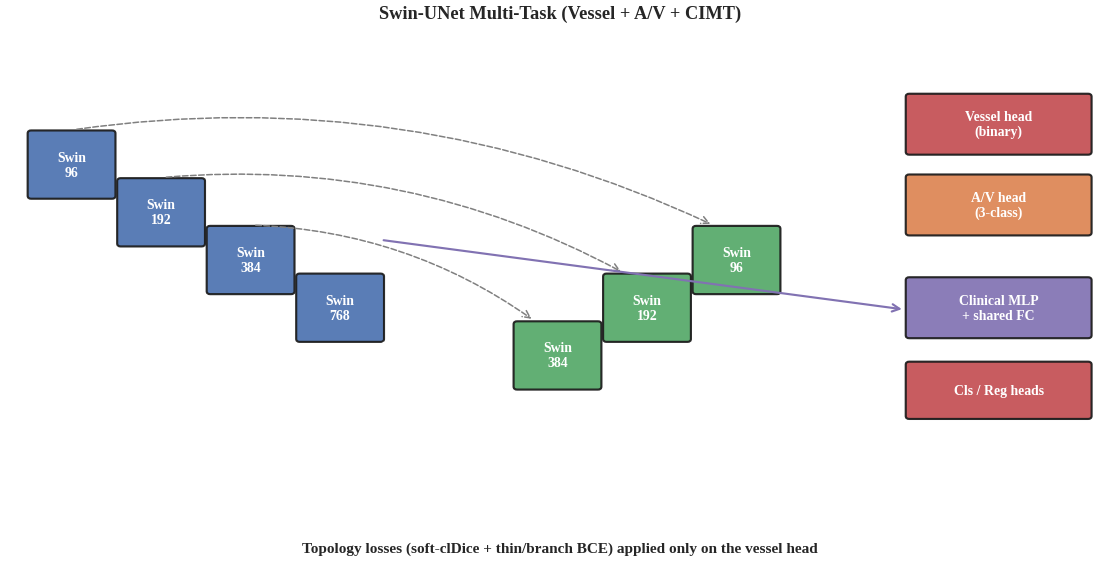

In [7]:
def draw_architecture():
    fig, ax = plt.subplots(figsize=(13, 6.5))
    ax.set_xlim(0, 13); ax.set_ylim(0, 7.5); ax.axis("off")
    colors = dict(enc="#4C72B0", dec="#55A868", head="#C44E52", clin="#8172B2", av="#DD8452")
    def box(x, y, w, h, txt, fc):
        ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.04", fc=fc, ec="k", lw=1.4, alpha=0.92))
        ax.text(x + w / 2, y + h / 2, txt, ha="center", va="center", fontsize=9, fontweight="bold",
                color="white", fontfamily="serif")
    E = CFG["embed_dim"]
    for i in range(4):
        box(0.3 + i * 1.05, 5.2 - i * 0.65, 0.95, 0.85, f"Swin\n{E * 2 ** i}", colors["enc"])
    for i, ch in enumerate([E * 4, E * 2, E]):
        box(6.0 + i * 1.05, 2.6 + i * 0.65, 0.95, 0.85, f"Swin\n{ch}", colors["dec"])
    ax.annotate("", xy=(5.9, 3.0), xytext=(4.4, 3.2), arrowprops=dict(arrowstyle="->", lw=1.6))
    for i in range(3):   # skip connections
        ax.annotate("", xy=(6.0 + (2 - i) * 1.05 + 0.2, 2.6 + (2 - i) * 0.65 + 0.9),
                    xytext=(0.3 + i * 1.05 + 0.5, 5.2 - i * 0.65 + 0.9),
                    arrowprops=dict(arrowstyle="->", lw=1.0, ls="--", color="gray",
                                    connectionstyle="arc3,rad=-0.15"))
    box(10.6, 5.8, 2.1, 0.75, "Vessel head\n(binary)", colors["head"])
    box(10.6, 4.7, 2.1, 0.75, "A/V head\n(3-class)", colors["av"])
    box(10.6, 3.3, 2.1, 0.75, "Clinical MLP\n+ shared FC", colors["clin"])
    box(10.6, 2.2, 2.1, 0.7, "Cls / Reg heads", colors["head"])
    ax.annotate("", xy=(10.55, 6.15), xytext=(9.3, 4.7), arrowprops=dict(arrowstyle="->", lw=1.4))
    ax.annotate("", xy=(10.55, 5.1), xytext=(9.3, 4.5), arrowprops=dict(arrowstyle="->", lw=1.4))
    ax.annotate("", xy=(10.55, 3.65), xytext=(4.4, 4.6), arrowprops=dict(arrowstyle="->", lw=1.4, color=colors["clin"]))
    ax.annotate("", xy=(11.65, 3.25), xytext=(11.65, 2.95), arrowprops=dict(arrowstyle="->", lw=1.4))
    ax.text(6.5, 0.35, "Topology losses (soft-clDice + thin/branch BCE) applied only on the vessel head",
            ha="center", fontsize=10, fontweight="bold", fontfamily="serif")
    ax.set_title("Swin-UNet Multi-Task (Vessel + A/V + CIMT)", fontweight="bold", fontfamily="serif", fontsize=FS)
    save_fig(fig, "architecture",
             "Network architecture. Shared Swin-UNet encoder–decoder produces a binary vessel mask "
             "(Task 3, topology-aware) and a 3-class Artery/Vein/Background mask (Task 4). "
             "Global bottleneck features + clinical variables feed the classification and regression heads.")

draw_architecture()

## 8. Parameter count

In [8]:
def component_params(m):
    cnt = lambda *mods: sum(p.numel() for mod in mods for p in mod.parameters())
    parts = [
        ("Patch embedding", cnt(m.patch_embed)),
        ("Encoder (Swin blocks + merging)", cnt(m.layers, m.norm)),
        ("Decoder (Swin blocks + expand + skip fusion)", cnt(m.layers_up, m.concat_back_dim, m.norm_up, m.up)),
        ("Vessel head", cnt(m.seg_head)),
        ("A/V head", cnt(m.av_head)),
        ("Clinical MLP + shared FC + cls/reg heads", cnt(m.clinical_mlp, m.shared_fc, m.cls_head, m.reg_head)),
    ]
    return pd.DataFrame(parts, columns=["Component", "Parameters"])

cp = component_params(model)
assert cp["Parameters"].sum() == n_params, "component table does not sum to total"
cp["Parameters (M)"] = cp["Parameters"] / 1e6
cp["Share (%)"] = 100 * cp["Parameters"] / cp["Parameters"].sum()
print(cp[["Component", "Parameters (M)", "Share (%)"]].round(3).to_string(index=False))
print("Total parameters:", f"{n_params:,}")

                                   Component  Parameters (M)  Share (%)
                             Patch embedding           0.005      0.018
             Encoder (Swin blocks + merging)          20.414     75.140
Decoder (Swin blocks + expand + skip fusion)           6.644     24.458
                                 Vessel head           0.000      0.000
                                    A/V head           0.000      0.001
    Clinical MLP + shared FC + cls/reg heads           0.104      0.383
Total parameters: 27,167,239


## 9. Losses (topology-aware vessel loss, A/V loss, CIMT losses)

In [9]:
# ---------------- soft morphology (differentiable) ----------------
def soft_erode(x):
    p1 = -F.max_pool2d(-x, (3, 1), (1, 1), (1, 0))
    p2 = -F.max_pool2d(-x, (1, 3), (1, 1), (0, 1))
    return torch.min(p1, p2)

def soft_dilate(x):
    return F.max_pool2d(x, (3, 3), (1, 1), (1, 1))

def soft_open(x):
    return soft_dilate(soft_erode(x))

def soft_skel(x, iters):
    img1 = soft_open(x)
    skel = F.relu(x - img1)
    for _ in range(iters):
        x = soft_erode(x)
        img1 = soft_open(x)
        delta = F.relu(x - img1)
        skel = skel + F.relu(delta - skel * delta)
    return skel

@torch.no_grad()
def topo_targets(gt, iters):
    # skeleton, thin-vessel map (width <= 2 px) and branch-point region of a binary GT mask (B,1,H,W)
    gt = gt.float()
    skel = soft_skel(gt, iters)
    thin = F.relu(gt - soft_open(gt)).clamp(0, 1)
    sk_bin = (skel > 0.5).float()
    nb = F.conv2d(sk_bin, torch.ones(1, 1, 3, 3, device=gt.device), padding=1)     # includes centre pixel
    branch = F.max_pool2d(sk_bin * (nb >= 4).float(), 5, 1, 2)                      # junction + 2 px neighbourhood
    return skel, thin, branch * gt


# ---------------- losses ----------------
class DiceLoss(nn.Module):
    def __init__(self, eps=1e-6):
        super().__init__(); self.eps = eps
    def forward(self, logits, target):
        p = torch.sigmoid(logits)
        inter = (p * target).sum((1, 2, 3))
        den = p.sum((1, 2, 3)) + target.sum((1, 2, 3))
        return (1 - (2 * inter + self.eps) / (den + self.eps)).mean()

class SoftclDiceLoss(nn.Module):
    def __init__(self, iters=10, eps=1.0):
        super().__init__(); self.iters, self.eps = iters, eps
    def forward(self, prob, target, skel_gt=None):
        skel_p = soft_skel(prob, self.iters)
        if skel_gt is None:
            skel_gt = soft_skel(target, self.iters)
        tprec = ((skel_p * target).sum((1, 2, 3)) + self.eps) / (skel_p.sum((1, 2, 3)) + self.eps)
        tsens = ((skel_gt * prob).sum((1, 2, 3)) + self.eps) / (skel_gt.sum((1, 2, 3)) + self.eps)
        return (1 - 2 * tprec * tsens / (tprec + tsens)).mean()

class TopoWeightedBCE(nn.Module):
    # BCE where thin vessels and branch regions get larger weights
    def __init__(self, thin_boost=2.0, branch_boost=4.0):
        super().__init__(); self.tb, self.bb = thin_boost, branch_boost
    def forward(self, logits, target, thin, branch):
        w = 1.0 + (self.tb - 1.0) * thin + (self.bb - 1.0) * branch
        l = F.binary_cross_entropy_with_logits(logits, target, reduction="none")
        return (l * w).sum() / w.sum()

class MultiClassDiceLoss(nn.Module):
    def __init__(self, n_classes=3, eps=1e-6):
        super().__init__(); self.n, self.eps = n_classes, eps
    def forward(self, logits, target, sample_w):
        p = F.softmax(logits, 1)
        oh = F.one_hot(target, self.n).permute(0, 3, 1, 2).float()
        inter = (p * oh).sum((2, 3)); den = p.sum((2, 3)) + oh.sum((2, 3))
        per = 1 - ((2 * inter + self.eps) / (den + self.eps)).mean(1)          # (B,)
        return (per * sample_w).sum() / sample_w.sum().clamp_min(1.0)

class MultiTaskLoss(nn.Module):
    def __init__(self, pos_weight, lam=0.5, w_cl=0.5, w_wb=0.5, cl_iters=10, thin_boost=2.0, branch_boost=4.0,
                 w_seg=1.0, w_cls=1.0, w_reg=1.0, w_av=1.0, n_av=3):
        super().__init__()
        self.register_buffer("pos_weight", pos_weight.float())
        self.lam, self.w_cl, self.w_wb, self.cl_iters = lam, w_cl, w_wb, cl_iters
        self.w_seg, self.w_cls, self.w_reg, self.w_av = w_seg, w_cls, w_reg, w_av
        self.dice, self.cldice = DiceLoss(), SoftclDiceLoss(cl_iters)
        self.wbce = TopoWeightedBCE(thin_boost, branch_boost)
        self.mc_dice = MultiClassDiceLoss(n_av)

    def forward(self, out, mask, av, has_av, lab, thick):
        with torch.autocast(device_type=mask.device.type, enabled=False):      # losses always in fp32
            seg_logit = out["seg"].float(); mask = mask.float()
            skel_gt, thin, branch = topo_targets(mask, self.cl_iters)
            bce = F.binary_cross_entropy_with_logits(seg_logit, mask)
            seg = ((1 - self.lam) * bce + self.lam * self.dice(seg_logit, mask)
                   + self.w_cl * self.cldice(torch.sigmoid(seg_logit), mask, skel_gt)
                   + self.w_wb * self.wbce(seg_logit, mask, thin, branch))

            cls = F.binary_cross_entropy_with_logits(out["cls"].float(), lab.float(), pos_weight=self.pos_weight)
            reg = F.smooth_l1_loss(out["reg"].float(), thick.float())

            av_logit = out["av"].float()
            if has_av.sum() > 0:
                ce = F.cross_entropy(av_logit, av, reduction="none").mean((1, 2))
                av_loss = (ce * has_av).sum() / has_av.sum() + self.mc_dice(av_logit, av, has_av)
            else:
                av_loss = av_logit.sum() * 0.0                                  # keeps graph valid when no A/V in batch

            total = self.w_seg * seg + self.w_cls * cls + self.w_reg * reg + self.w_av * av_loss
        return total, dict(seg=seg.detach(), cls=cls.detach(), reg=reg.detach(), av=av_loss.detach())


pos = int((train_df["label"] == 1).sum()); neg = int((train_df["label"] == 0).sum())
pos_weight = torch.tensor([neg / max(pos, 1)], device=device, dtype=torch.float32)

criterion = MultiTaskLoss(
    pos_weight, lam=CFG["lam"], w_cl=CFG["w_cl"], w_wb=CFG["w_wb"], cl_iters=CFG["cl_iters"],
    thin_boost=CFG["thin_boost"], branch_boost=CFG["branch_boost"],
    w_seg=CFG["w_seg"], w_cls=CFG["w_cls"], w_reg=CFG["w_reg"], w_av=CFG["w_av"]).to(device)
print(f"pos_weight (neg/pos) = {pos_weight.item():.3f}")

# quick loss sanity check on one real batch
model.train()
_img, _m, _av, _hav, _cl, _lab, _th = [t.to(device) for t in next(iter(train_loader))]
with autocast_ctx():
    _o = model(_img, _cl)
_l, _parts = criterion(_o, _m, _av, _hav, _lab, _th)
print("loss:", float(_l), {k: round(float(v), 4) for k, v in _parts.items()})
assert torch.isfinite(_l)
del _img, _m, _av, _hav, _cl, _lab, _th, _o, _l, _parts
if device.type == "cuda":
    torch.cuda.empty_cache()

pos_weight (neg/pos) = 0.367
loss: 3.9729185104370117 {'seg': 1.553, 'cls': 0.2481, 'reg': 0.2514, 'av': 1.9204}


## 10. Metrics and evaluation helpers

In [10]:
EPS = 1e-6

@torch.no_grad()
def seg_metrics(pred_bin, gt, iters):
    # per-image vessel metrics; pred_bin, gt: (B,1,H,W) float {0,1}
    d = (1, 2, 3)
    tp = (pred_bin * gt).sum(d)
    dice = (2 * tp + EPS) / (pred_bin.sum(d) + gt.sum(d) + EPS)
    iou  = (tp + EPS) / (pred_bin.sum(d) + gt.sum(d) - tp + EPS)
    prec = (tp + EPS) / (pred_bin.sum(d) + EPS)
    rec  = (tp + EPS) / (gt.sum(d) + EPS)
    sp, sg = soft_skel(pred_bin, iters), soft_skel(gt, iters)
    tprec = ((sp * gt).sum(d) + EPS) / (sp.sum(d) + EPS)
    tsens = ((sg * pred_bin).sum(d) + EPS) / (sg.sum(d) + EPS)
    cld = 2 * tprec * tsens / (tprec + tsens + EPS)
    _, thin, branch = topo_targets(gt, iters)
    nan = torch.full_like(dice, float("nan"))
    thin_rec = torch.where(thin.sum(d) > 0, (pred_bin * thin).sum(d) / thin.sum(d).clamp_min(1), nan)
    br_rec = torch.where(branch.sum(d) > 0, (pred_bin * branch).sum(d) / branch.sum(d).clamp_min(1), nan)
    return dict(dice=dice, iou=iou, prec=prec, rec=rec, cldice=cld, tprec=tprec, tsens=tsens,
                thin_rec=thin_rec, branch_rec=br_rec)

@torch.no_grad()
def av_dice(pred, gt, has_av):
    # per-image Dice for artery(1) and vein(2); NaN if no A/V annotation or class absent in GT
    out = {}
    for c, name in ((1, "av_art"), (2, "av_vein")):
        p, g = (pred == c).float(), (gt == c).float()
        inter, den = (p * g).sum((1, 2)), p.sum((1, 2)) + g.sum((1, 2))
        dc = (2 * inter + EPS) / (den + EPS)
        valid = (has_av > 0) & (g.sum((1, 2)) > 0)
        out[name] = torch.where(valid, dc, torch.full_like(dc, float("nan")))
    return out

@torch.no_grad()
def evaluate(model, loader, crit=None):
    model.eval()
    keys = ["prob", "lab", "reg", "thick", "dice", "iou", "prec", "rec", "cldice", "tprec", "tsens",
            "thin_rec", "branch_rec", "av_art", "av_vein"]
    R = {k: [] for k in keys}
    tot, n = 0.0, 0
    for batch in loader:
        img, mask, av, has_av, clin, lab, thick = [b.to(device, non_blocking=True) for b in batch]
        with autocast_ctx():
            out = model(img, clin)
        if crit is not None:
            loss, _ = crit(out, mask, av, has_av, lab, thick)
            tot += float(loss) * img.size(0)
        n += img.size(0)
        pred_bin = (torch.sigmoid(out["seg"].float()) > 0.5).float()
        sm = seg_metrics(pred_bin, mask.float(), CFG["cl_iters"])
        am = av_dice(out["av"].argmax(1), av, has_av)
        R["prob"].append(torch.sigmoid(out["cls"].float())); R["lab"].append(lab)
        R["reg"].append(out["reg"].float()); R["thick"].append(thick)
        for k, v in {**sm, **am}.items():
            R[k].append(v)
    R = {k: torch.cat(v).float().cpu().numpy() for k, v in R.items()}
    R["reg_mm"]   = R["reg"] * SCALER["t_sd"] + SCALER["t_mu"]
    R["thick_mm"] = R["thick"] * SCALER["t_sd"] + SCALER["t_mu"]
    R["loss"] = tot / max(n, 1) if crit is not None else float("nan")
    return R

def safe_auc(y, p):
    y = np.asarray(y).astype(int)
    return float(roc_auc_score(y, p)) if len(np.unique(y)) > 1 else float("nan")

def epoch_summary(R):
    return dict(loss=R["loss"], dice=nm(R["dice"]), cldice=nm(R["cldice"]),
                auc=safe_auc(R["lab"], R["prob"]),
                mae_mm=float(np.mean(np.abs(R["reg_mm"] - R["thick_mm"]))),
                av_dice=nm([nm(R["av_art"]), nm(R["av_vein"])]))

# ---------- full metric set (used for test table, bootstrap, subgroups) ----------
def cls_metrics(y, p, thr):
    y = np.asarray(y).astype(int); yhat = (p >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, yhat, labels=[0, 1]).ravel()
    sens = tp / max(tp + fn, 1); spec = tn / max(tn + fp, 1); prec = tp / max(tp + fp, 1)
    f1 = 2 * prec * sens / max(prec + sens, 1e-12)
    mcc = float(matthews_corrcoef(y, yhat)) if len(np.unique(yhat)) > 1 and len(np.unique(y)) > 1 else 0.0
    return {"AUC": safe_auc(y, p), "Accuracy": (tp + tn) / len(y), "Sensitivity": sens, "Specificity": spec,
            "Precision": prec, "F1": f1, "MCC": mcc, "Brier": float(brier_score_loss(y, p))}

def reg_metrics(t, p):
    err = p - t
    ss_res, ss_tot = float((err ** 2).sum()), float(((t - t.mean()) ** 2).sum())
    r = float(pearsonr(t, p)[0]) if len(t) > 2 and np.std(t) > 0 and np.std(p) > 0 else float("nan")
    return {"MAE (mm)": float(np.abs(err).mean()), "RMSE (mm)": float(np.sqrt((err ** 2).mean())),
            "R2": 1 - ss_res / ss_tot if ss_tot > 0 else float("nan"), "Pearson r": r}

def all_metrics(R, idx, thr):
    m = {}
    m.update(cls_metrics(R["lab"][idx], R["prob"][idx], thr))
    m.update(reg_metrics(R["thick_mm"][idx], R["reg_mm"][idx]))
    m.update({"Dice": nm(R["dice"][idx]), "IoU": nm(R["iou"][idx]), "clDice": nm(R["cldice"][idx]),
              "Topo. precision": nm(R["tprec"][idx]), "Topo. sensitivity": nm(R["tsens"][idx]),
              "Thin-vessel recall": nm(R["thin_rec"][idx]), "Branch-region recall": nm(R["branch_rec"][idx]),
              "Artery Dice": nm(R["av_art"][idx]), "Vein Dice": nm(R["av_vein"][idx])})
    m["A/V mean Dice"] = nm([m["Artery Dice"], m["Vein Dice"]])
    return m

def cluster_bootstrap(fn, patients, B, seed=42):
    # patient-level (cluster) bootstrap: both eyes of a patient are resampled together
    rng = np.random.default_rng(seed)
    uniq, inv = np.unique(patients, return_inverse=True)
    groups = [np.where(inv == i)[0] for i in range(len(uniq))]
    point = fn(np.arange(len(patients)))
    samp = {k: [] for k in point}
    for _ in range(B):
        pick = rng.integers(0, len(groups), len(groups))
        try:
            r = fn(np.concatenate([groups[i] for i in pick]))
        except Exception:
            continue
        for k, v in r.items():
            samp[k].append(v)
    res = {}
    for k, v in point.items():
        arr = np.asarray(samp[k], dtype=float)
        lo, hi = (np.nanpercentile(arr, 2.5), np.nanpercentile(arr, 97.5)) if np.isfinite(arr).any() else (np.nan, np.nan)
        res[k] = (v, lo, hi)
    return res

def youden_threshold(y, p):
    y = np.asarray(y).astype(int)
    if len(np.unique(y)) < 2:
        return 0.5
    fpr, tpr, thr = roc_curve(y, p)
    t = thr[np.argmax(tpr - fpr)]
    return float(t) if np.isfinite(t) else 0.5
print("evaluation helpers ready")

evaluation helpers ready


## 11. Training

In [11]:
best_ckpt = os.path.join(CKPT_DIR, "swinunet_multitask_av_best.pth")
hist_csv  = os.path.join(CFG["out_dir"], "swinunet_multitask_av_history.csv")

def train_one_epoch(model, loader, crit, opt, scaler):
    model.train()
    acc = dict(loss=0.0, seg=0.0, cls=0.0, reg=0.0, av=0.0); n = 0; skipped = 0
    for batch in loader:
        img, mask, av, has_av, clin, lab, thick = [b.to(device, non_blocking=True) for b in batch]
        opt.zero_grad(set_to_none=True)
        with autocast_ctx():
            out = model(img, clin)
        loss, parts = crit(out, mask, av, has_av, lab, thick)
        if not torch.isfinite(loss):
            skipped += 1; continue
        scaler.scale(loss).backward()
        scaler.unscale_(opt)
        torch.nn.utils.clip_grad_norm_(model.parameters(), CFG["grad_clip"])
        scaler.step(opt); scaler.update()
        bs = img.size(0); n += bs
        acc["loss"] += float(loss) * bs
        for k, v in parts.items():
            acc[k] += float(v) * bs
    if skipped:
        print(f"  (skipped {skipped} non-finite batches)")
    return {k: v / max(n, 1) for k, v in acc.items()}

history = []
if RUN_TRAINING:
    opt = torch.optim.AdamW(model.parameters(), lr=CFG["lr"], weight_decay=CFG["weight_decay"])
    warm = max(1, CFG["epochs"] // 10)
    lr_lambda = lambda e: (e + 1) / warm if e < warm else \
        0.01 + 0.99 * 0.5 * (1 + math.cos(math.pi * (e - warm) / max(1, CFG["epochs"] - warm)))
    sched = torch.optim.lr_scheduler.LambdaLR(opt, lr_lambda)
    scaler = make_scaler()
    best_val, bad = float("inf"), 0
    t_start = time.time()
    for ep in range(1, CFG["epochs"] + 1):
        t0 = time.time()
        tr = train_one_epoch(model, train_loader, criterion, opt, scaler)
        va = epoch_summary(evaluate(model, val_loader, criterion))
        lr_now = opt.param_groups[0]["lr"]
        sched.step()
        history.append(dict(epoch=ep, lr=lr_now, **{f"train_{k}": v for k, v in tr.items()},
                            **{f"val_{k}": v for k, v in va.items()}))
        improved = np.isfinite(va["loss"]) and va["loss"] < best_val
        if improved:
            best_val, bad = va["loss"], 0
            torch.save({"model": model.state_dict(), "epoch": ep, "val_loss": best_val}, best_ckpt)
        else:
            bad += 1
        print(f"ep {ep:02d}/{CFG['epochs']} | {time.time() - t0:5.0f}s | train {tr['loss']:.4f} | val {va['loss']:.4f} "
              f"| Dice {va['dice']:.3f} clDice {va['cldice']:.3f} | AUC {va['auc']:.3f} | MAE {va['mae_mm']:.3f} mm "
              f"| A/V {va['av_dice']:.3f} {'*' if improved else ''}")
        pd.DataFrame(history).to_csv(hist_csv, index=False)
        if bad >= CFG["patience"]:
            print(f"early stopping at epoch {ep} (no val-loss improvement for {CFG['patience']} epochs)")
            break
    print(f"training done in {(time.time() - t_start) / 60:.1f} min | best val loss {best_val:.4f}")
elif os.path.exists(hist_csv):
    history = pd.read_csv(hist_csv).to_dict("records")

assert os.path.exists(best_ckpt), f"No checkpoint at {best_ckpt}. Set RUN_TRAINING = True."
ckpt = torch.load(best_ckpt, map_location=device)
model.load_state_dict(ckpt["model"])
print(f"loaded best checkpoint from epoch {ckpt['epoch']} (val loss {ckpt['val_loss']:.4f})")
hist_df = pd.DataFrame(history)

ep 01/30 |   590s | train 2.3261 | val 2.2440 | Dice 0.732 clDice 0.724 | AUC 0.750 | MAE 0.186 mm | A/V 0.431 *
ep 02/30 |   497s | train 1.7122 | val 1.7780 | Dice 0.817 clDice 0.811 | AUC 0.860 | MAE 0.167 mm | A/V 0.588 *
ep 03/30 |   497s | train 1.3665 | val 1.4217 | Dice 0.856 clDice 0.868 | AUC 0.869 | MAE 0.136 mm | A/V 0.669 *
ep 04/30 |   497s | train 1.2209 | val 1.3242 | Dice 0.879 clDice 0.887 | AUC 0.868 | MAE 0.141 mm | A/V 0.723 *
ep 05/30 |   497s | train 1.1558 | val 1.3615 | Dice 0.888 clDice 0.894 | AUC 0.871 | MAE 0.141 mm | A/V 0.751 
ep 06/30 |   497s | train 1.1119 | val 1.2563 | Dice 0.886 clDice 0.900 | AUC 0.870 | MAE 0.139 mm | A/V 0.768 *
ep 07/30 |   497s | train 1.0864 | val 1.2161 | Dice 0.889 clDice 0.905 | AUC 0.869 | MAE 0.140 mm | A/V 0.788 *
ep 08/30 |   497s | train 1.0607 | val 1.1752 | Dice 0.897 clDice 0.909 | AUC 0.870 | MAE 0.135 mm | A/V 0.806 *
ep 09/30 |   497s | train 1.0422 | val 1.2186 | Dice 0.897 clDice 0.912 | AUC 0.870 | MAE 0.144 m

## 12. Implementation details and complexity (Tables 2–3)

In [12]:
dev_name = torch.cuda.get_device_name(0) if device.type == "cuda" else "CPU"
impl = [
    ("Backbone", "Swin-UNet (window-based Transformer encoder–decoder, patch size 4)"),
    ("Embedding dim / depths / heads", f"{CFG['embed_dim']} / {CFG['depths']} / {CFG['num_heads']}"),
    ("Decoder depths / window size", f"{CFG['depths_decoder']} / {CFG['window_size']}"),
    ("Stochastic depth", CFG["drop_path_rate"]),
    ("Input size", f"{CFG['img_size']} × {CFG['img_size']} RGB"),
    ("Optimizer", f"AdamW (lr {CFG['lr']}, weight decay {CFG['weight_decay']}), warm-up + cosine schedule"),
    ("Batch size / max epochs / patience", f"{CFG['batch_size']} / {CFG['epochs']} / {CFG['patience']}"),
    ("Mixed precision / grad. clipping", f"{USE_AMP} / {CFG['grad_clip']}"),
    ("Vessel loss", f"(1−λ)·BCE + λ·Dice + {CFG['w_cl']}·soft-clDice + {CFG['w_wb']}·thin/branch BCE (λ = {CFG['lam']})"),
    ("Topology settings", f"soft-skeleton iters {CFG['cl_iters']}, thin ×{CFG['thin_boost']}, branch ×{CFG['branch_boost']}"),
    ("A/V loss", "Cross-entropy + multi-class Dice (only images with A/V annotation)"),
    ("CIMT losses", "Class-weighted BCE (classification), Smooth-L1 on standardised thickness (regression)"),
    ("Task weights (seg / cls / reg / A/V)", f"{CFG['w_seg']} / {CFG['w_cls']} / {CFG['w_reg']} / {CFG['w_av']}"),
    ("Augmentation", "Horizontal flip, rotation ±15°, Gaussian noise (train only)"),
    ("Clinical inputs", "Age (z-scored with training statistics), gender"),
    ("Model selection", "Lowest total validation loss; classification threshold chosen on validation (Youden J)"),
    ("Uncertainty", f"Patient-level bootstrap, {CFG['boot_iters']} resamples, 95% percentile CI"),
    ("Seed / hardware", f"{CFG['seed']} / {dev_name}"),
]
show_table(pd.DataFrame(impl, columns=["Item", "Setting"]), "implementation_details",
           "Implementation details of the proposed model.", align="left")

# ---------- model complexity (Table 3) ----------
def measure_complexity(model):
    S = CFG["img_size"]; model.eval()
    x, c = torch.randn(1, 3, S, S, device=device), torch.randn(1, 2, device=device)
    gflops = float("nan")
    try:
        from torch.utils.flop_counter import FlopCounterMode
        with torch.no_grad(), FlopCounterMode(display=False) as fc:
            model(x, c)
        gflops = fc.get_total_flops() / 1e9
    except Exception as e:
        print("  (FLOP counting skipped:", type(e).__name__, ")")
    with torch.no_grad():
        for _ in range(3):
            model(x, c)
        if device.type == "cuda": torch.cuda.synchronize()
        t0 = time.time(); reps = 10
        for _ in range(reps):
            model(x, c)
        if device.type == "cuda": torch.cuda.synchronize()
    ms = (time.time() - t0) / reps * 1000
    return gflops, ms

gflops, inf_ms = measure_complexity(model)
tab3 = pd.DataFrame([{
    "Model": "Swin-UNet Multi-Task + A/V",
    "Parameters (M)": n_params / 1e6,
    "GFLOPs (1 image)": gflops,
    "Inference (ms / image)": inf_ms,
    "Input": f"{CFG['img_size']}×{CFG['img_size']}",
}])
show_table(tab3, "model_complexity", "Model complexity and inference cost.", precision=2,
           note=f"Measured on {dev_name}, batch size 1, fp32.")

Item,Setting
Backbone,"Swin-UNet (window-based Transformer encoder–decoder, patch size 4)"
Embedding dim / depths / heads,"96 / [2, 2, 2, 2] / [3, 6, 12, 24]"
Decoder depths / window size,"[1, 2, 2, 2] / 8"
Stochastic depth,0.1000
Input size,512 × 512 RGB
Optimizer,"AdamW (lr 0.0001, weight decay 1e-05), warm-up + cosine schedule"
Batch size / max epochs / patience,4 / 30 / 10
Mixed precision / grad. clipping,True / 1.0
Vessel loss,(1−λ)·BCE + λ·Dice + 0.5·soft-clDice + 0.5·thin/branch BCE (λ = 0.5)
Topology settings,"soft-skeleton iters 10, thin ×2.0, branch ×4.0"


Model,Parameters (M),GFLOPs (1 image),Inference (ms / image),Input
Swin-UNet Multi-Task + A/V,27.17,60.25,48.44,512×512


## 13. Test evaluation with patient-level bootstrap (Tables 4–6)

In [13]:
val_R  = evaluate(model, val_loader, criterion)
test_R = evaluate(model, test_loader, criterion)

THR = youden_threshold(val_R["lab"], val_R["prob"])
print(f"classification threshold (Youden on validation) = {THR:.3f}")
print("TEST:", {k: round(v, 4) for k, v in epoch_summary(test_R).items()})

test_pat = test_df["patient"].values
assert len(test_pat) == len(test_R["prob"]), "test arrays and test_df are out of sync"
boot = cluster_bootstrap(lambda idx: all_metrics(test_R, idx, THR), test_pat, CFG["boot_iters"], CFG["seed"])

def row(task, key, d=4):
    m, lo, hi = boot[key]
    return {"Task": task, "Metric": key, "Estimate (95% CI)": fmt_ci(m, lo, hi, d) if np.isfinite(m) else "–"}

rows  = [row("Task 1: CIMT classification", k) for k in ["AUC", "Accuracy", "Sensitivity", "Specificity", "Precision", "F1", "MCC", "Brier"]]
rows += [row("Task 2: CIMT regression", k) for k in ["MAE (mm)", "RMSE (mm)", "R2", "Pearson r"]]
rows += [row("Task 3: Vessel segmentation", k) for k in ["Dice", "IoU", "clDice"]]
rows += [row("Task 4: A/V segmentation", k) for k in ["Artery Dice", "Vein Dice", "A/V mean Dice"]]
tab4 = pd.DataFrame(rows)
show_table(tab4, "main_test_results", "Main results on the held-out test set (patient-level bootstrap, 95% CI).",
           align="left",
           note=f"Classification threshold = {THR:.3f} (Youden index on validation). Segmentation metrics are image-level means. A/V Dice computed only on test images with A/V annotation.")

# ---------- Table 5: subgroup analysis (point estimates) ----------
age_cut = float(train_df[AGE_COL].median())
tdf = test_df.reset_index(drop=True)
groups = []
for g, nme in GENDER_NAMES.items():
    groups.append(("Gender", nme, np.where(tdf["gender"].values == g)[0]))
groups.append(("Age", f"< {age_cut:.0f} years", np.where(tdf[AGE_COL].values < age_cut)[0]))
groups.append(("Age", f"≥ {age_cut:.0f} years", np.where(tdf[AGE_COL].values >= age_cut)[0]))
for c, nme in CLASS_NAMES.items():
    groups.append(("CIMT class", nme, np.where(tdf["label"].values == c)[0]))
srows = []
for var, lvl, idx in groups:
    if len(idx) < 5:
        continue
    m = all_metrics(test_R, idx, THR)
    srows.append({"Subgroup": var, "Level": lvl, "n": len(idx),
                  "AUC": m["AUC"], "Accuracy": m["Accuracy"], "MAE (mm)": m["MAE (mm)"],
                  "Dice": m["Dice"], "clDice": m["clDice"]})
tab5 = pd.DataFrame(srows)
show_table(tab5, "subgroup_analysis", "Subgroup analysis on the test set (point estimates).", precision=3,
           note="AUC is undefined (–) inside the single-class CIMT subgroups.")

# ---------- Table 6: topology / thin vessel / A/V ----------
keys6 = ["Dice", "clDice", "Topo. precision", "Topo. sensitivity", "Thin-vessel recall",
         "Branch-region recall", "Artery Dice", "Vein Dice", "A/V mean Dice"]
tab6 = pd.DataFrame([{"Metric": k, "Estimate (95% CI)": fmt_ci(*boot[k]) if np.isfinite(boot[k][0]) else "–"} for k in keys6])
show_table(tab6, "topology_metrics", "Topology-aware, thin-vessel and artery–vein metrics on the test set.",
           align="left", note="Thin vessel = width ≤ 2 px at the working resolution; branch region = 2 px neighbourhood of skeleton junctions.")

classification threshold (Youden on validation) = 0.651
TEST: {'loss': 0.8253, 'dice': 0.9074, 'cldice': 0.927, 'auc': 0.9437, 'mae_mm': 0.1068, 'av_dice': 0.8768}


Task,Metric,Estimate (95% CI)
Task 1: CIMT classification,AUC,0.9437 (0.8969–0.9811)
Task 1: CIMT classification,Accuracy,0.8900 (0.8300–0.9450)
Task 1: CIMT classification,Sensitivity,0.8700 (0.7778–0.9479)
Task 1: CIMT classification,Specificity,0.9100 (0.8333–0.9792)
Task 1: CIMT classification,Precision,0.9062 (0.8242–0.9775)
Task 1: CIMT classification,F1,0.8878 (0.8243–0.9445)
Task 1: CIMT classification,MCC,0.7806 (0.6612–0.8910)
Task 1: CIMT classification,Brier,0.1030 (0.0720–0.1383)
Task 2: CIMT regression,MAE (mm),0.1068 (0.0897–0.1239)
Task 2: CIMT regression,RMSE (mm),0.1372 (0.1178–0.1559)


Subgroup,Level,n,AUC,Accuracy,MAE (mm),Dice,clDice
Gender,Gender 0,74,0.900,0.851,0.113,0.908,0.926
Gender,Gender 1,126,0.955,0.913,0.103,0.907,0.928
Age,< 50 years,108,0.812,0.898,0.110,0.909,0.929
Age,≥ 50 years,92,0.754,0.880,0.103,0.906,0.925
CIMT class,Class 0,100,–,0.910,0.130,0.908,0.929
CIMT class,Class 1,100,–,0.870,0.084,0.907,0.925


Metric,Estimate (95% CI)
Dice,0.9074 (0.9047–0.9100)
clDice,0.9270 (0.9248–0.9291)
Topo. precision,0.9124 (0.9092–0.9156)
Topo. sensitivity,0.9423 (0.9397–0.9447)
Thin-vessel recall,0.8587 (0.8515–0.8654)
Branch-region recall,0.9426 (0.9401–0.9446)
Artery Dice,0.8606 (0.8549–0.8654)
Vein Dice,0.8931 (0.8896–0.8963)
A/V mean Dice,0.8768 (0.8726–0.8809)


## 14. Figures 3–6

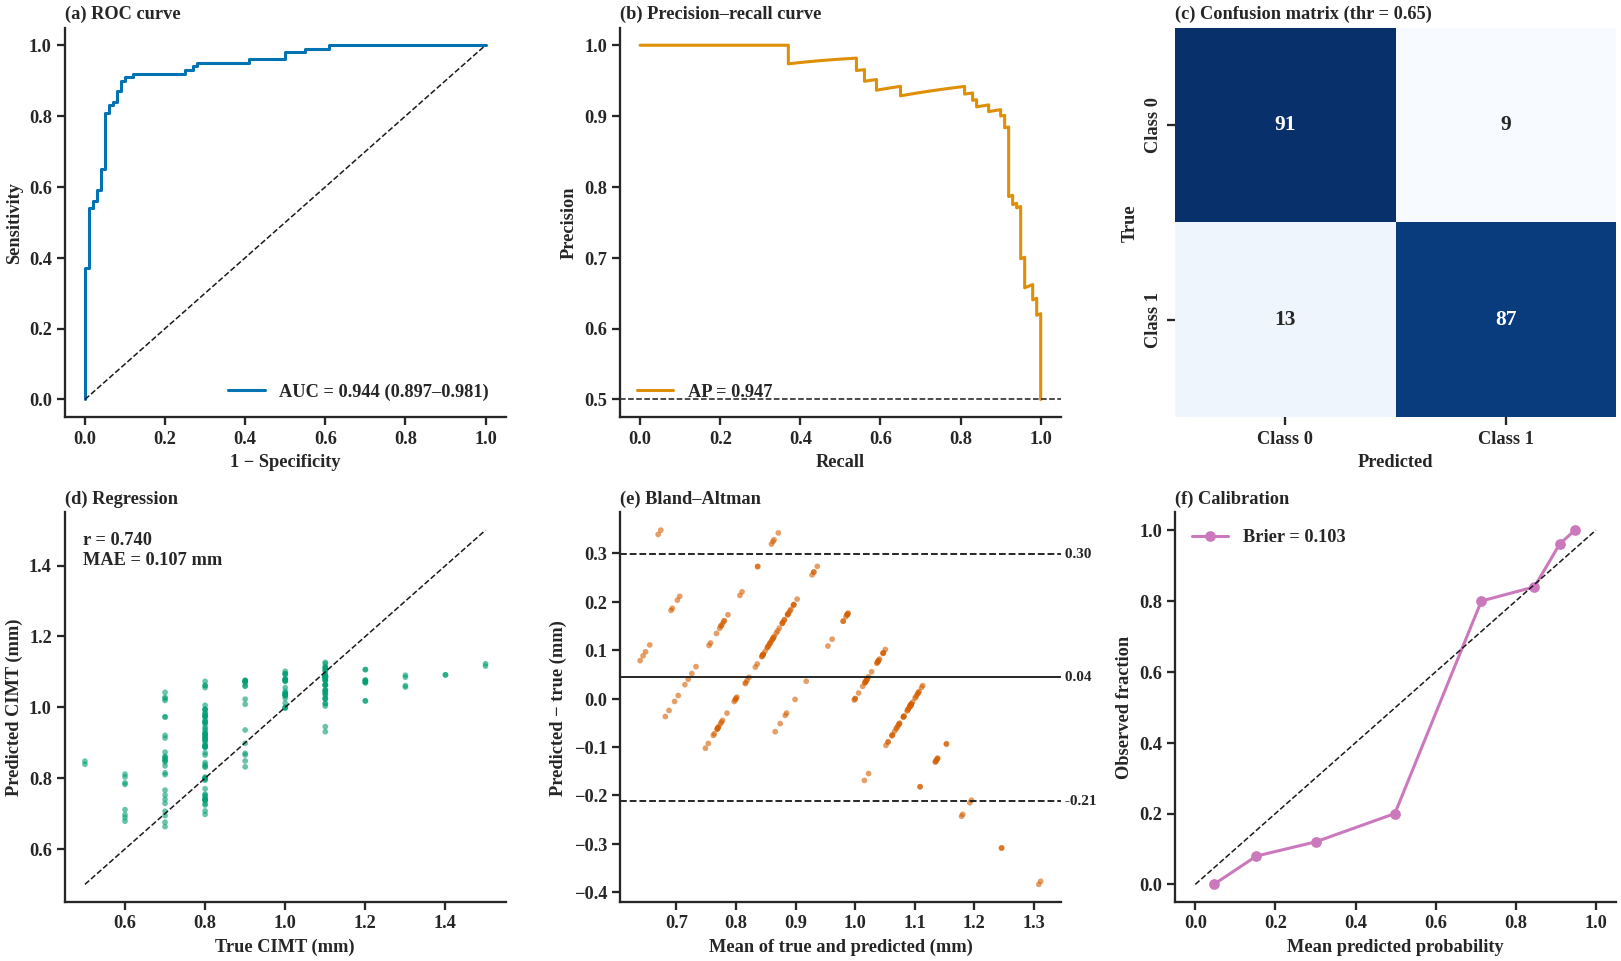

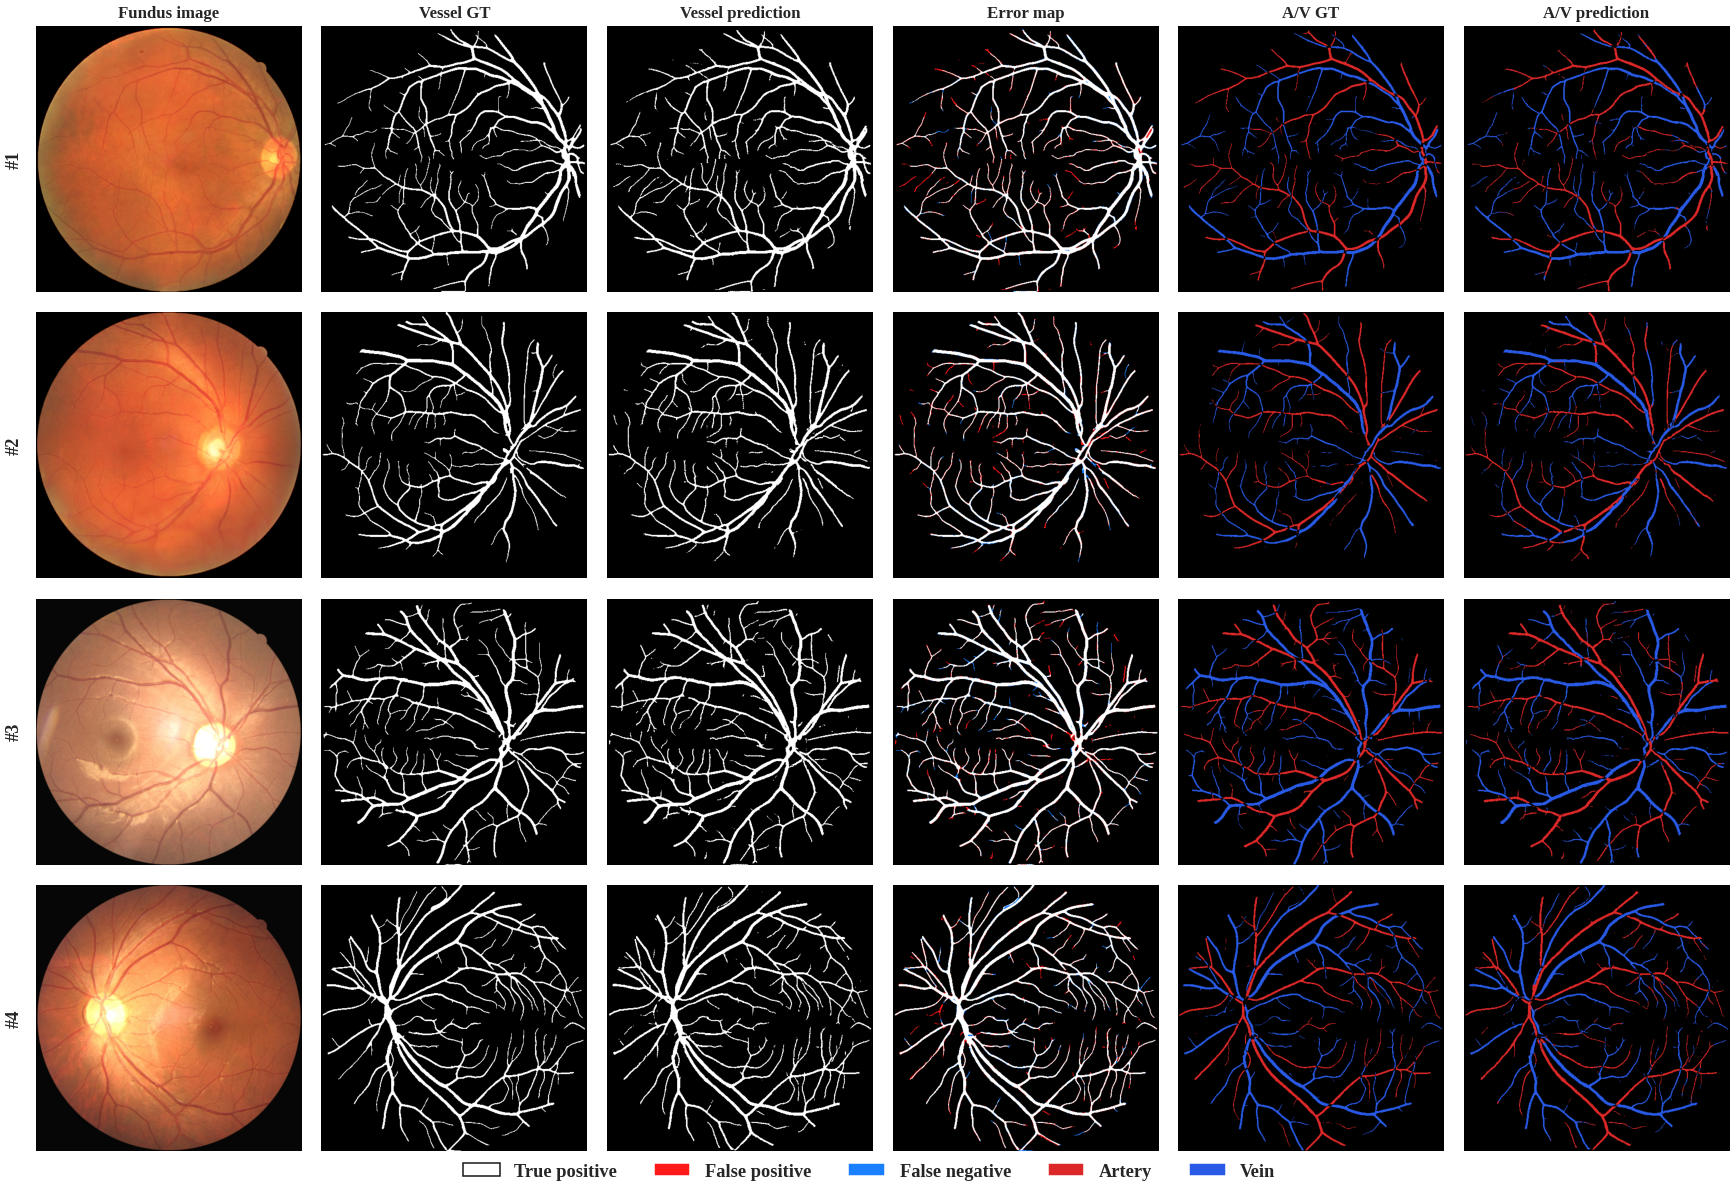

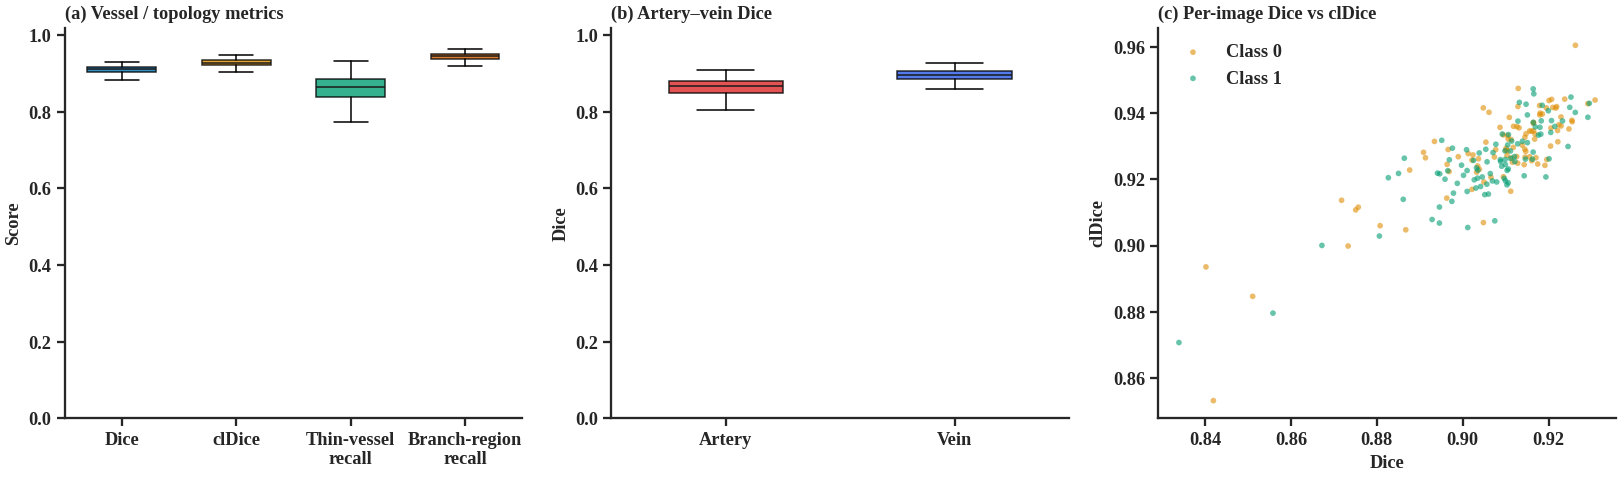

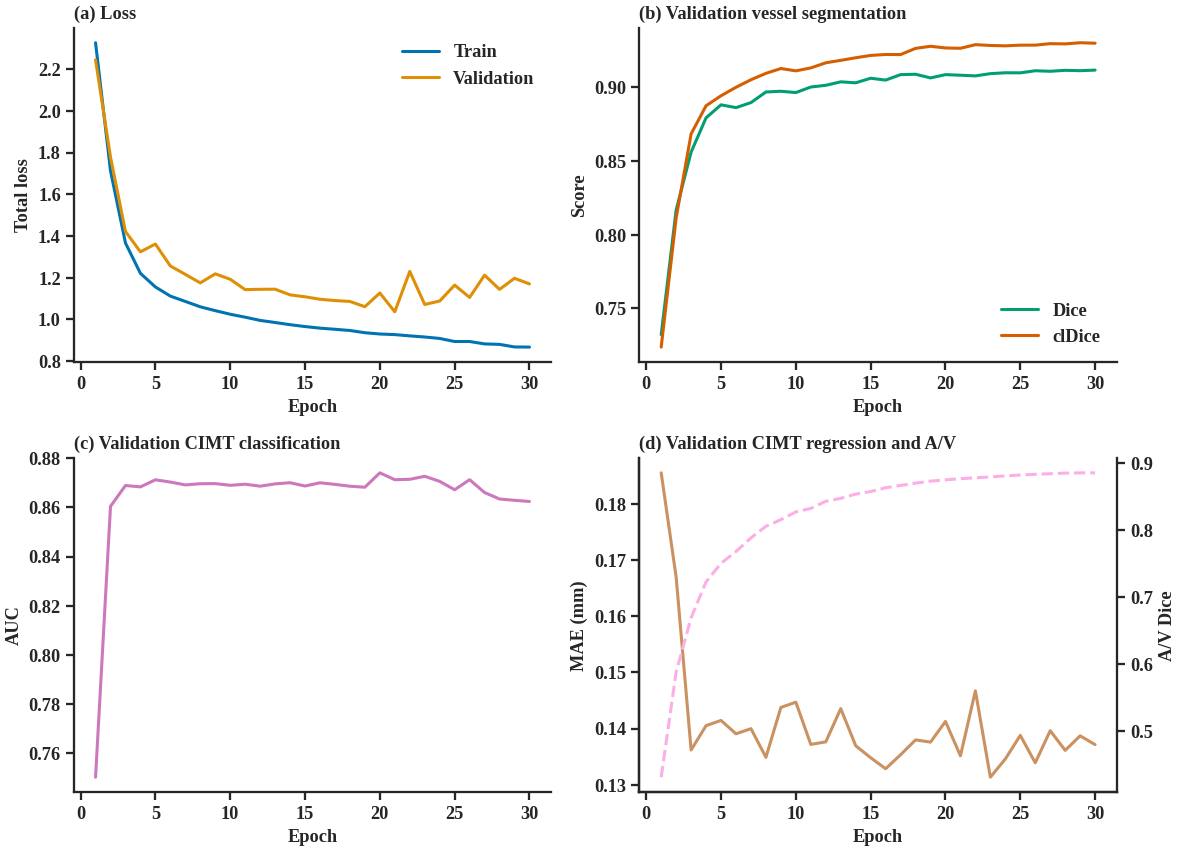

In [14]:
# ---------------- Fig. 3: test performance ----------------
with safe("fig3"):
    y, p = test_R["lab"].astype(int), test_R["prob"]
    t_true, t_pred = test_R["thick_mm"], test_R["reg_mm"]
    fig, axes = plt.subplots(2, 3, figsize=(15, 9))
    # (a) ROC
    ax = axes[0, 0]
    if len(np.unique(y)) > 1:
        fpr, tpr, _ = roc_curve(y, p)
        a, lo, hi = boot["AUC"]
        ax.plot(fpr, tpr, color=PAL[0], label=f"AUC = {a:.3f} ({lo:.3f}–{hi:.3f})")
    ax.plot([0, 1], [0, 1], "k--", lw=1); ax.set_xlabel("1 − Specificity"); ax.set_ylabel("Sensitivity")
    ax.legend(loc="lower right"); ttl(ax, "a", "ROC curve")
    # (b) PR
    ax = axes[0, 1]
    if len(np.unique(y)) > 1:
        pr, rc, _ = precision_recall_curve(y, p)
        ax.plot(rc, pr, color=PAL[1], label=f"AP = {average_precision_score(y, p):.3f}")
        ax.axhline(y.mean(), color="k", ls="--", lw=1)
    ax.set_xlabel("Recall"); ax.set_ylabel("Precision"); ax.legend(loc="lower left"); ttl(ax, "b", "Precision–recall curve")
    # (c) confusion matrix
    ax = axes[0, 2]
    cm = confusion_matrix(y, (p >= THR).astype(int), labels=[0, 1])
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax, annot_kws=dict(fontsize=FS + 2, fontweight="bold"),
                xticklabels=[CLASS_NAMES[0], CLASS_NAMES[1]], yticklabels=[CLASS_NAMES[0], CLASS_NAMES[1]])
    ax.set_xlabel("Predicted"); ax.set_ylabel("True"); ttl(ax, "c", f"Confusion matrix (thr = {THR:.2f})")
    # (d) scatter
    ax = axes[1, 0]
    ax.scatter(t_true, t_pred, s=14, alpha=0.6, color=PAL[2], edgecolor="none")
    lim = [min(t_true.min(), t_pred.min()), max(t_true.max(), t_pred.max())]
    ax.plot(lim, lim, "k--", lw=1)
    ax.text(0.04, 0.95, f"r = {boot['Pearson r'][0]:.3f}\nMAE = {boot['MAE (mm)'][0]:.3f} mm", transform=ax.transAxes, va="top")
    ax.set_xlabel("True CIMT (mm)"); ax.set_ylabel("Predicted CIMT (mm)"); ttl(ax, "d", "Regression")
    # (e) Bland-Altman
    ax = axes[1, 1]
    diff, mean = t_pred - t_true, (t_pred + t_true) / 2
    bias, sd = diff.mean(), diff.std(ddof=1)
    ax.scatter(mean, diff, s=14, alpha=0.6, color=PAL[3], edgecolor="none")
    for v, ls in ((bias, "-"), (bias + 1.96 * sd, "--"), (bias - 1.96 * sd, "--")):
        ax.axhline(v, color="k", ls=ls, lw=1.2)
        ax.text(ax.get_xlim()[1], v, f" {v:.2f}", va="center", fontsize=FS - 2)
    ax.set_xlabel("Mean of true and predicted (mm)"); ax.set_ylabel("Predicted − true (mm)"); ttl(ax, "e", "Bland–Altman")
    # (f) calibration
    ax = axes[1, 2]
    try:
        pt, pp = calibration_curve(y, p, n_bins=8, strategy="quantile")
        ax.plot(pp, pt, "o-", color=PAL[4], label=f"Brier = {boot['Brier'][0]:.3f}")
    except Exception as e:
        print("calibration skipped:", e)
    ax.plot([0, 1], [0, 1], "k--", lw=1); ax.set_xlabel("Mean predicted probability"); ax.set_ylabel("Observed fraction")
    ax.legend(loc="upper left"); ttl(ax, "f", "Calibration")
    plt.tight_layout()
    save_fig(fig, "test_performance",
             "Test performance. (a) ROC curve with 95% CI of the AUC. (b) Precision–recall curve. (c) Confusion matrix at the validation-selected threshold. "
             "(d) Predicted vs. true CIMT. (e) Bland–Altman plot (solid = bias, dashed = 95% limits of agreement). (f) Calibration curve.")

# ---------------- Fig. 4: qualitative ----------------
AV_RGB = np.array([[0, 0, 0], [220, 40, 40], [40, 90, 230]], dtype=np.uint8)

@torch.no_grad()
def predict_one(ds, i):
    img, mask, av, has_av, clin, lab, th = ds[i]
    model.eval()
    with autocast_ctx():
        out = model(img.unsqueeze(0).to(device), clin.unsqueeze(0).to(device))
    seg = (torch.sigmoid(out["seg"].float())[0, 0] > 0.5).cpu().numpy()
    avp = out["av"].argmax(1)[0].cpu().numpy()
    return img.permute(1, 2, 0).numpy(), mask[0].numpy() > 0.5, seg, av.numpy(), avp, bool(has_av > 0)

with safe("fig4"):
    cand = np.where(np.isfinite(test_R["av_art"]))[0]
    pool = cand if len(cand) >= 4 else np.arange(len(test_ds))
    sel = pool[np.linspace(0, len(pool) - 1, 4).astype(int)]
    cols = ["Fundus image", "Vessel GT", "Vessel prediction", "Error map", "A/V GT", "A/V prediction"]
    fig, axes = plt.subplots(len(sel), 6, figsize=(16, 2.7 * len(sel)))
    for r, i in enumerate(sel):
        im, gt, pr, avg, avp, hav = predict_one(test_ds, int(i))
        err = np.zeros(gt.shape + (3,), dtype=np.float32)
        err[gt & pr] = (1, 1, 1); err[~gt & pr] = (1, 0.1, 0.1); err[gt & ~pr] = (0.1, 0.5, 1)
        panels = [im, gt, pr, err, AV_RGB[avg] if hav else np.zeros_like(im), AV_RGB[avp]]
        for c, pnl in enumerate(panels):
            ax = axes[r, c]
            ax.imshow(pnl, cmap="gray" if (c in (1, 2)) else None); ax.axis("off")
            if r == 0:
                ax.set_title(cols[c], fontsize=FS - 1)
        axes[r, 0].text(-0.05, 0.5, f"#{r + 1}", transform=axes[r, 0].transAxes, rotation=90, va="center", ha="right")
    fig.legend(handles=[Patch(fc="w", ec="k", label="True positive"), Patch(fc=(1, .1, .1), label="False positive"),
                        Patch(fc=(.1, .5, 1), label="False negative"), Patch(fc=AV_RGB[1] / 255, label="Artery"),
                        Patch(fc=AV_RGB[2] / 255, label="Vein")], loc="lower center", ncol=5, bbox_to_anchor=(0.5, -0.02))
    plt.tight_layout()
    save_fig(fig, "qualitative",
             "Qualitative results on test images. Columns: fundus image, vessel ground truth (GT), predicted vessel mask, error map, A/V GT (black if no annotation), predicted A/V map.")

# ---------------- Fig. 5: topology quantitative ----------------
with safe("fig5"):
    fig, axes = plt.subplots(1, 3, figsize=(15, 4.6))
    names = ["Dice", "clDice", "Thin-vessel\nrecall", "Branch-region\nrecall"]
    data = [test_R["dice"], test_R["cldice"], test_R["thin_rec"], test_R["branch_rec"]]
    data = [d[np.isfinite(d)] for d in data]
    bp = axes[0].boxplot(data, patch_artist=True, showfliers=False, widths=0.6); axes[0].set_xticklabels(names)
    for patch, col in zip(bp["boxes"], PAL):
        patch.set_facecolor(col); patch.set_alpha(0.8)
    for el in ("medians",):
        for l in bp[el]: l.set_color("k")
    axes[0].set_ylabel("Score"); axes[0].set_ylim(0, 1.02); ttl(axes[0], "a", "Vessel / topology metrics")
    av_data = [test_R["av_art"][np.isfinite(test_R["av_art"])], test_R["av_vein"][np.isfinite(test_R["av_vein"])]]
    if all(len(d) > 0 for d in av_data):
        bp = axes[1].boxplot(av_data, patch_artist=True, showfliers=False, widths=0.5); axes[1].set_xticklabels(["Artery", "Vein"])
        for patch, col in zip(bp["boxes"], (AV_RGB[1] / 255, AV_RGB[2] / 255)):
            patch.set_facecolor(col); patch.set_alpha(0.8)
        for l in bp["medians"]: l.set_color("k")
    else:
        axes[1].text(0.5, 0.5, "no A/V annotation\nin test set", ha="center", transform=axes[1].transAxes)
    axes[1].set_ylabel("Dice"); axes[1].set_ylim(0, 1.02); ttl(axes[1], "b", "Artery–vein Dice")
    for lab, col in ((0, PAL[1]), (1, PAL[2])):
        mk = test_R["lab"] == lab
        axes[2].scatter(test_R["dice"][mk], test_R["cldice"][mk], s=14, alpha=0.6, color=col, label=CLASS_NAMES[lab], edgecolor="none")
    axes[2].set_xlabel("Dice"); axes[2].set_ylabel("clDice"); axes[2].legend(); ttl(axes[2], "c", "Per-image Dice vs clDice")
    plt.tight_layout()
    save_fig(fig, "topology_quantitative",
             "Quantitative topology evaluation on the test set. (a) Per-image Dice, clDice, thin-vessel recall and branch-region recall. "
             "(b) Artery and vein Dice. (c) Relationship between Dice and clDice per image, coloured by CIMT class.")

# ---------------- Fig. 6: training curves ----------------
with safe("fig6"):
    h = hist_df
    if len(h) == 0:
        print("no training history available -> Fig. 6 skipped")
    else:
        fig, axes = plt.subplots(2, 2, figsize=(11, 8))
        axes[0, 0].plot(h["epoch"], h["train_loss"], label="Train", color=PAL[0])
        axes[0, 0].plot(h["epoch"], h["val_loss"], label="Validation", color=PAL[1])
        axes[0, 0].set_xlabel("Epoch"); axes[0, 0].set_ylabel("Total loss"); axes[0, 0].legend(); ttl(axes[0, 0], "a", "Loss")
        axes[0, 1].plot(h["epoch"], h["val_dice"], label="Dice", color=PAL[2])
        axes[0, 1].plot(h["epoch"], h["val_cldice"], label="clDice", color=PAL[3])
        axes[0, 1].set_xlabel("Epoch"); axes[0, 1].set_ylabel("Score"); axes[0, 1].legend(); ttl(axes[0, 1], "b", "Validation vessel segmentation")
        axes[1, 0].plot(h["epoch"], h["val_auc"], color=PAL[4])
        axes[1, 0].set_xlabel("Epoch"); axes[1, 0].set_ylabel("AUC"); ttl(axes[1, 0], "c", "Validation CIMT classification")
        ax2 = axes[1, 1]
        ax2.plot(h["epoch"], h["val_mae_mm"], color=PAL[5], label="MAE (mm)")
        ax2.set_xlabel("Epoch"); ax2.set_ylabel("MAE (mm)")
        ax3 = ax2.twinx(); ax3.spines["right"].set_visible(True)
        ax3.plot(h["epoch"], h["val_av_dice"], color=PAL[6], ls="--", label="A/V Dice"); ax3.set_ylabel("A/V Dice")
        ttl(ax2, "d", "Validation CIMT regression and A/V")
        plt.tight_layout()
        save_fig(fig, "training_curves", "Training curves. (a) Total loss. (b) Validation Dice and clDice. (c) Validation AUC. (d) Validation CIMT MAE (solid) and A/V Dice (dashed).")

## 15. Export

In [15]:
summary = pd.DataFrame([{**{k: v[0] for k, v in boot.items()}, "threshold": THR, "params_M": n_params / 1e6,
                         "best_epoch": int(ckpt["epoch"])}], index=["Swin-UNet Multi-Task + A/V (test)"])
summary_path = os.path.join(CFG["out_dir"], "swinunet_multitask_av_test_summary.csv")
summary.to_csv(summary_path)
pd.DataFrame({"image": test_df["base"], "patient": test_df["patient"], "label": test_R["lab"].astype(int),
              "prob": test_R["prob"], "thickness_true_mm": test_R["thick_mm"], "thickness_pred_mm": test_R["reg_mm"],
              "dice": test_R["dice"], "cldice": test_R["cldice"], "artery_dice": test_R["av_art"], "vein_dice": test_R["av_vein"]}
             ).to_csv(os.path.join(CFG["out_dir"], "swinunet_multitask_av_test_predictions.csv"), index=False)

zip_path = os.path.join(CFG["out_dir"], "journal_outputs.zip")
with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
    for folder in (FIG_DIR, TAB_DIR):
        for fn in sorted(os.listdir(folder)):
            z.write(os.path.join(folder, fn), os.path.join(os.path.basename(folder), fn))
    for extra in (summary_path, hist_csv):
        if os.path.exists(extra):
            z.write(extra, os.path.basename(extra))

print("Figures:"); [print("  ", r["label"], "-", r["stem"]) for r in FIG_REGISTRY]
print("Tables:");  [print("  ", r["label"], "-", r["stem"]) for r in TAB_REGISTRY]
print("checkpoint :", best_ckpt)
print("summary    :", summary_path)
print("zip bundle :", zip_path, f"({os.path.getsize(zip_path) / 1e6:.1f} MB)")
display(summary.T)

Figures:
   Fig. 1 - dataset_overview
   Fig. 2 - architecture
   Fig. 3 - test_performance
   Fig. 4 - qualitative
   Fig. 5 - topology_quantitative
   Fig. 6 - training_curves
Tables:
   Table 1 - dataset_characteristics
   Table 2 - implementation_details
   Table 3 - model_complexity
   Table 4 - main_test_results
   Table 5 - subgroup_analysis
   Table 6 - topology_metrics
checkpoint : /kaggle/working/swinunet_multitask_av_best.pth
summary    : /kaggle/working/swinunet_multitask_av_test_summary.csv
zip bundle : /kaggle/working/journal_outputs.zip (66.0 MB)


,Swin-UNet Multi-Task + A/V (test)
AUC,0.943700
Accuracy,0.890000
Sensitivity,0.870000
Specificity,0.910000
Precision,0.906250
F1,0.887755
MCC,0.780625
Brier,0.102968
MAE (mm),0.106846
RMSE (mm),0.137203
